In [1]:

from __future__ import print_function, division
from collections import defaultdict, OrderedDict
import gzip
import pickle
import json
import os
import uproot
import matplotlib.pyplot as plt
%matplotlib inline
import numpy as np
from coffea import hist, processor 
from coffea.hist import plot
from coffea.util import load, save

In [24]:
bkg_hists

{'template': <Hist (process,region,systematic,mT_corrected) instance at 0x7f4cbf6f9630>,
 'ele_phi': <Hist (process,region,systematic,ele_phi) instance at 0x7f4cbf003908>,
 'sumw': <Hist (process,sumw) instance at 0x7f4cbefd6a20>,
 'j1pt': <Hist (process,region,systematic,j1pt) instance at 0x7f4cbefd9ba8>,
 'eT_miss_corrected_phi': <Hist (process,region,systematic,eT_miss_corrected_phi) instance at 0x7f4cbef66cf8>,
 'metphi': <Hist (process,region,systematic,metphi) instance at 0x7f4cbee84dd8>,
 'ndflvM': <Hist (process,region,systematic,ndflvM) instance at 0x7f4cbee23f28>,
 'dr_mu_lj': <Hist (process,region,systematic,dr_mu_lj) instance at 0x7f4cbed94048>,
 'ele_pT': <Hist (process,region,systematic,ele_pT) instance at 0x7f4cbed25128>,
 'mu_eta': <Hist (process,region,systematic,mu_eta) instance at 0x7f4cbec96240>,
 'j1phi': <Hist (process,region,systematic,j1phi) instance at 0x7f4cbebc5358>,
 'leading_mu_pT': <Hist (process,region,systematic,leading_mu_pT) instance at 0x7f4cbeb64438>

In [32]:
bkg_hists['template'].integrate('region', 'wjete').integrate('systematic', 'nominal').integrate('process', 'W+HF').values()



{(): array([0.00000000e+00, 6.50130281e+02, 1.81266008e+03, 1.34631112e+03,
        1.45130511e+03, 1.56420150e+03, 8.50125991e+02, 4.35984712e+02,
        1.79617092e+02, 1.07000314e+02, 5.21139897e+01, 3.17748969e+01,
        2.45516423e+01, 1.18297735e+01, 1.07345780e+01, 9.91696647e+00,
        2.55126400e+00, 3.93576071e+00, 1.95538686e+00, 9.92114548e-01])}

In [24]:
bkg_hists['template'].identifiers('systematic')

[<StringBin (JERDown) instance at 0x7f5d1d584668>,
 <StringBin (JERUp) instance at 0x7f5d1d5845f8>,
 <StringBin (JESDown) instance at 0x7f5d1d584588>,
 <StringBin (JESUp) instance at 0x7f5d1d584518>,
 <StringBin (METunclDown) instance at 0x7f5d1d5846d8>,
 <StringBin (METunclUp) instance at 0x7f5d1d5846a0>,
 <StringBin (btagDown) instance at 0x7f5d1d5840b8>,
 <StringBin (btagUp) instance at 0x7f5d1d584080>,
 <StringBin (ew1Down) instance at 0x7f5d1d584b70>,
 <StringBin (ew1Up) instance at 0x7f5d1d584b00>,
 <StringBin (ew2GDown) instance at 0x7f5d1d584c18>,
 <StringBin (ew2GUp) instance at 0x7f5d1d584be0>,
 <StringBin (ew2WDown) instance at 0x7f5d1d584cc0>,
 <StringBin (ew2WUp) instance at 0x7f5d1d584c88>,
 <StringBin (ew2ZDown) instance at 0x7f5d1d584d68>,
 <StringBin (ew2ZUp) instance at 0x7f5d1d584d30>,
 <StringBin (ew3GDown) instance at 0x7f5d1d584e10>,
 <StringBin (ew3GUp) instance at 0x7f5d1d584dd8>,
 <StringBin (ew3WDown) instance at 0x7f5d1d584eb8>,
 <StringBin (ew3WUp) instance 

In [33]:
bkg_hists['mT_corrected'].integrate('region', 'wjete').integrate('systematic', 'nominal').integrate('process',"W+HF").values()

{(): array([0.00000000e+00, 6.50130281e+02, 1.81266008e+03, 1.34631112e+03,
        1.45130511e+03, 1.56420150e+03, 8.50125991e+02, 4.35984712e+02,
        1.79617092e+02, 1.07000314e+02, 5.21139897e+01, 3.17748969e+01,
        2.45516423e+01, 1.18297735e+01, 1.07345780e+01, 9.91696647e+00,
        2.55126400e+00, 3.93576071e+00, 1.95538686e+00, 9.92114548e-01])}

In [2]:
hists = load('../../../hists/UL_lep_monotop_v1_test_2018.scaled')
data={
    '2018':{
        'sre': 'EGamma',
        'srm': 'SingleMuon',
        'wjetm': 'SingleMuon',
        'ttbarm': 'SingleMuon',
        'wjete': 'EGamma',
        'ttbare': 'EGamma',
#         'zmcr': 'MET',
#         'zecr': 'EGamma',
#         'gcr': 'EGamma'
    }
}

data_hists   = hists['data']
bkg_hists    = hists['bkg']
signal_hists = hists['sig']

In [19]:
data_hists['mT_corrected'].integrate('region','wjete').integrate('systematic', 'nominal')

<Hist (process,mT_corrected) instance at 0x7f4cbf7cf208>

In [18]:
bkg_hists['mT_corrected'].integrate('region','wjete').integrate('systematic', 'nominal')

<Hist (process,mT_corrected) instance at 0x7f4cc730ec50>

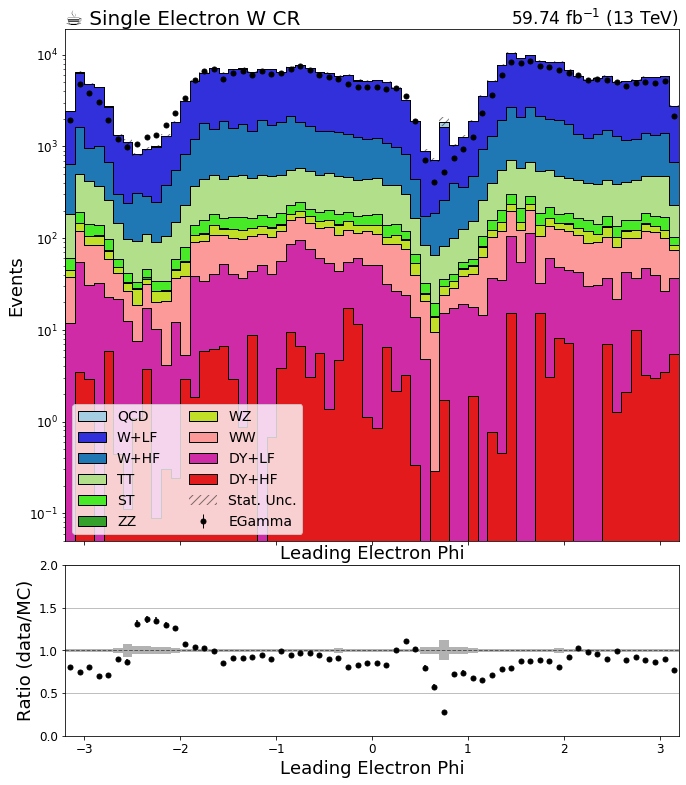

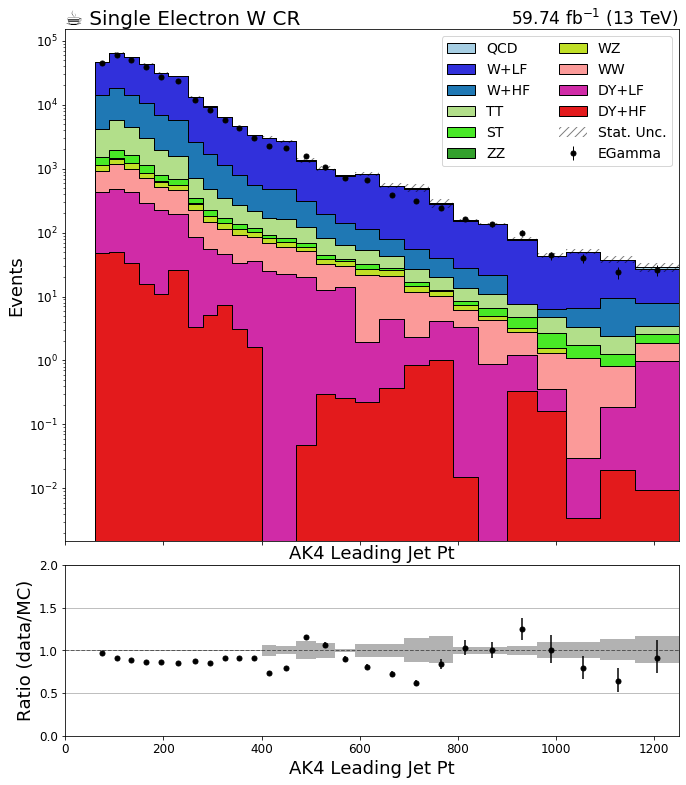

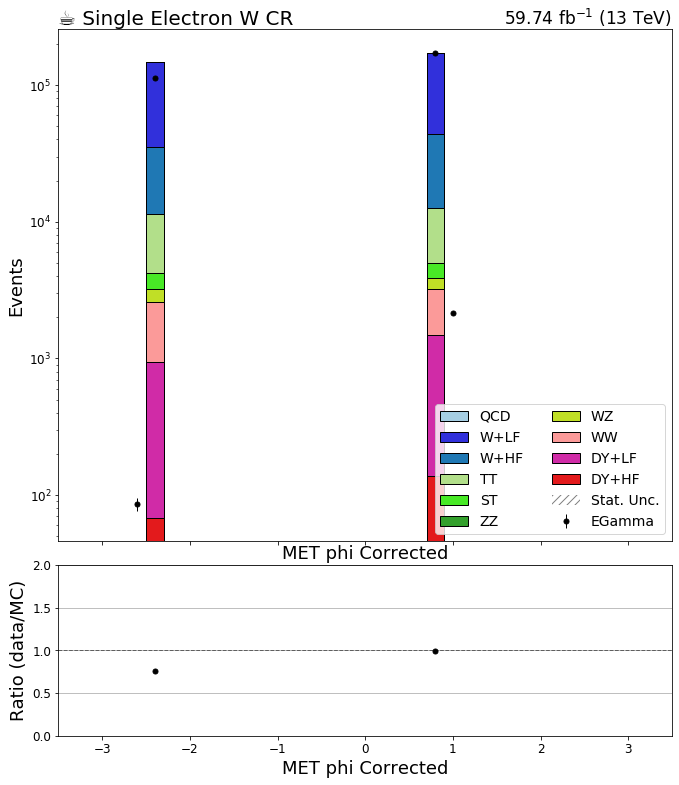

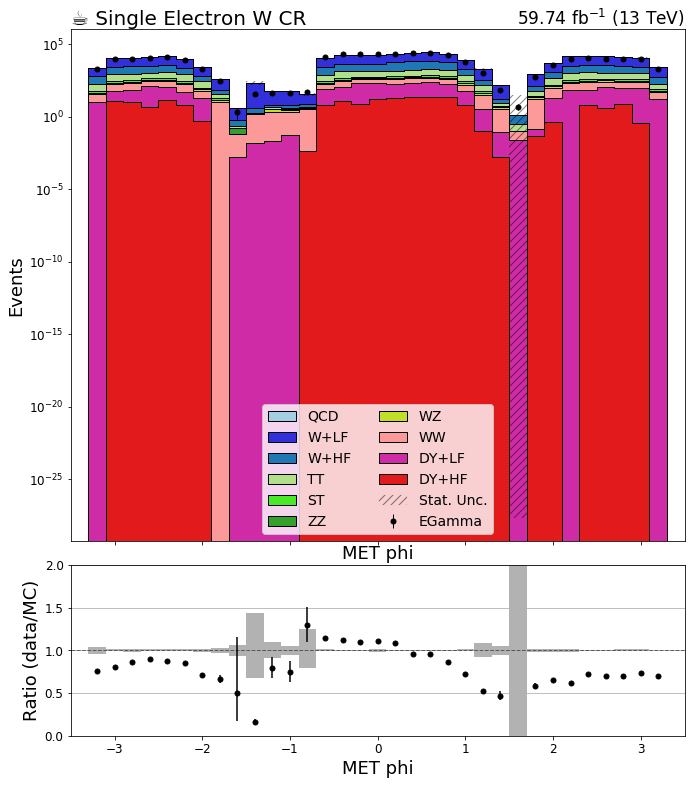

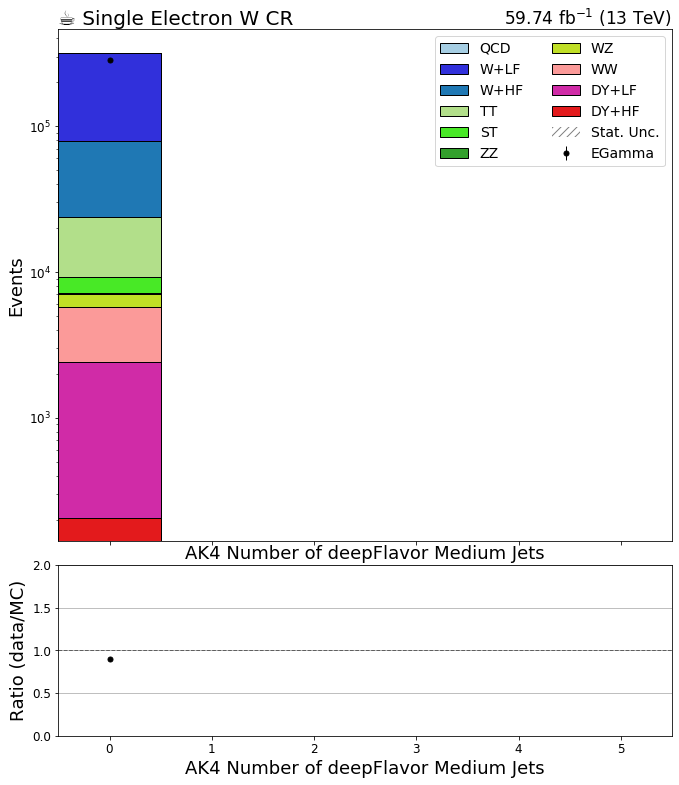

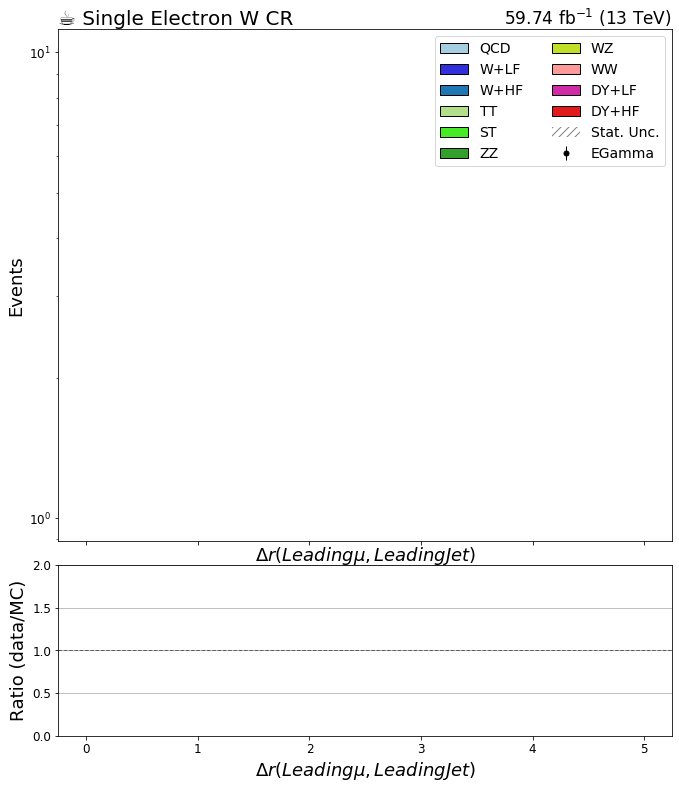

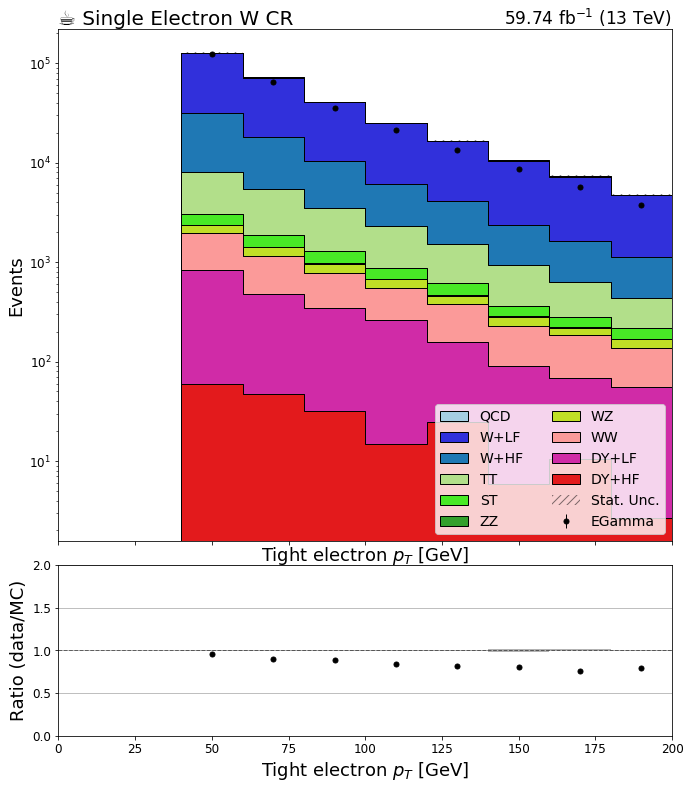

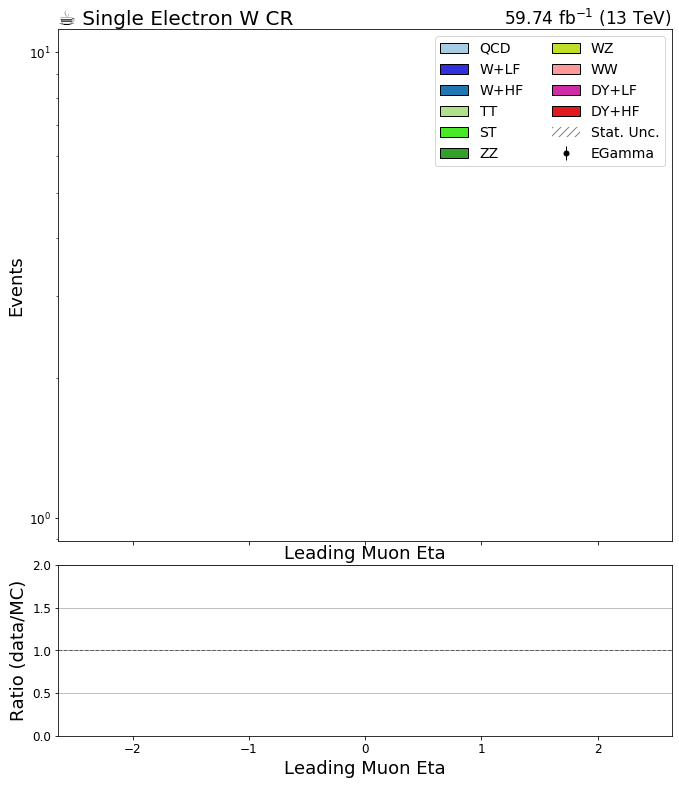

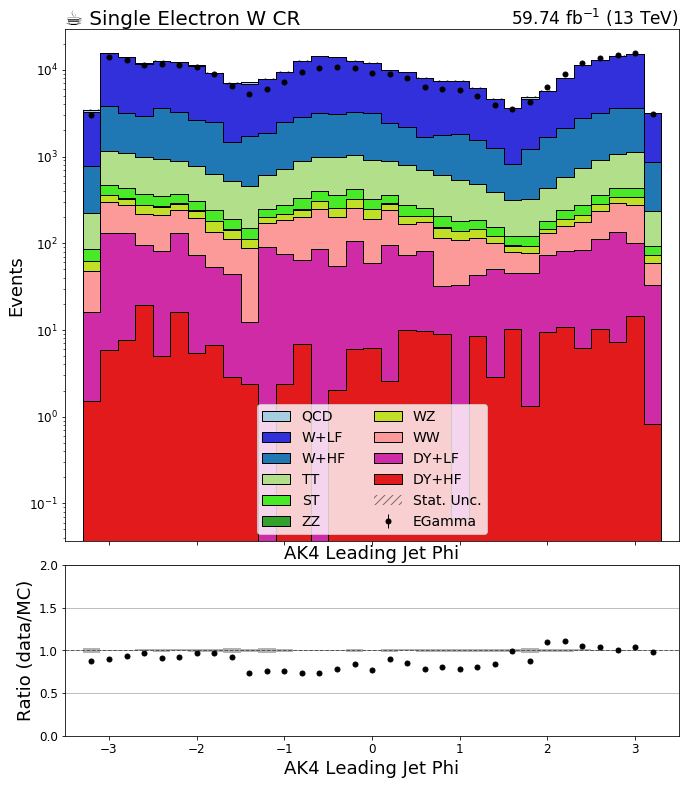

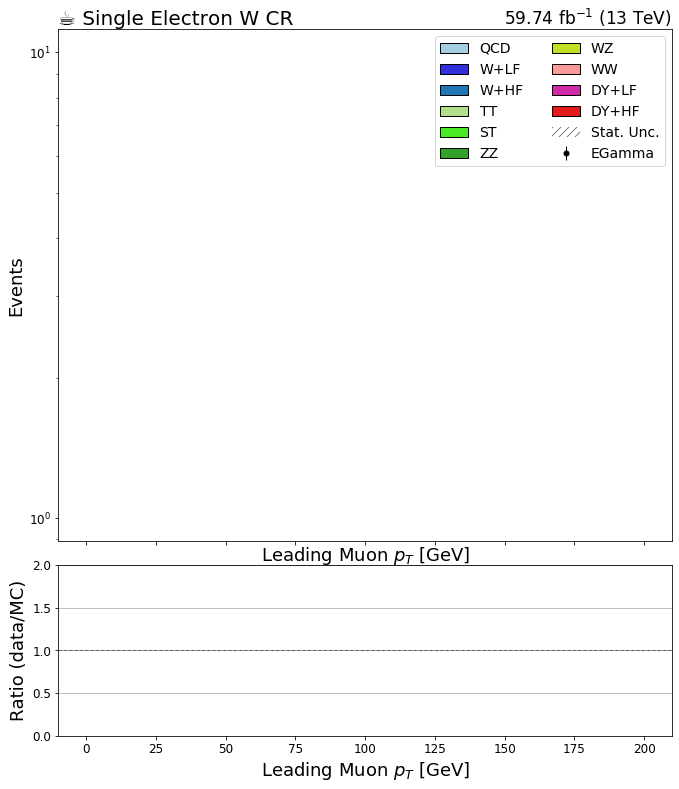

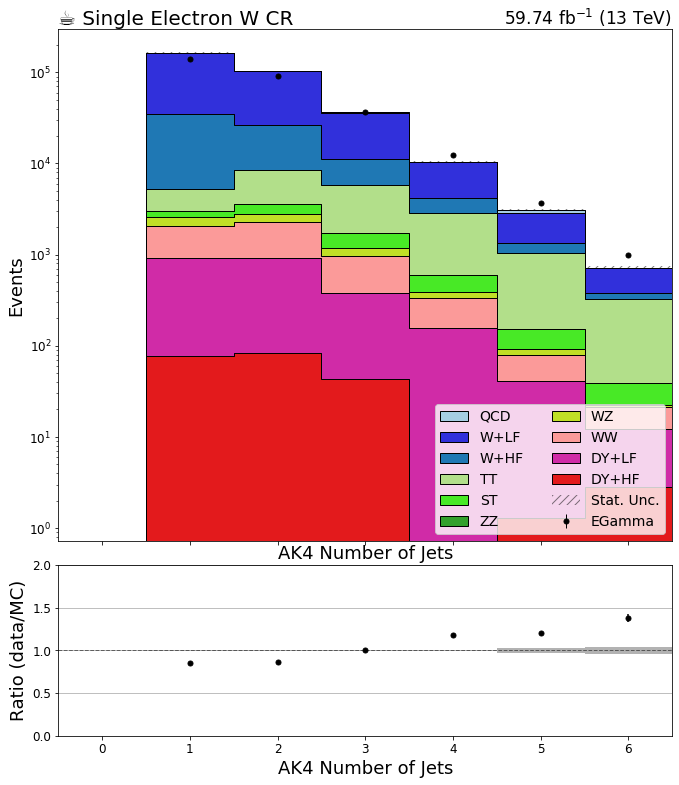

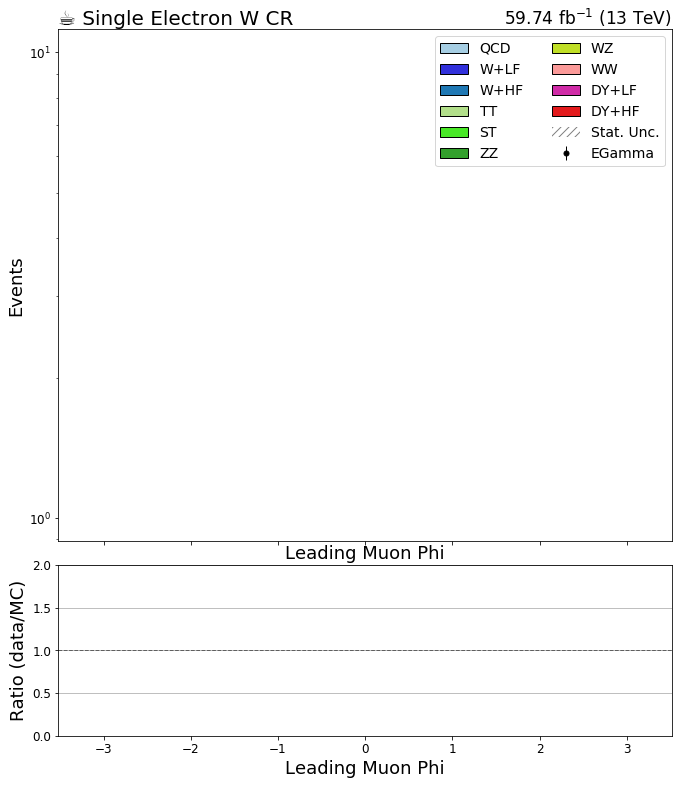

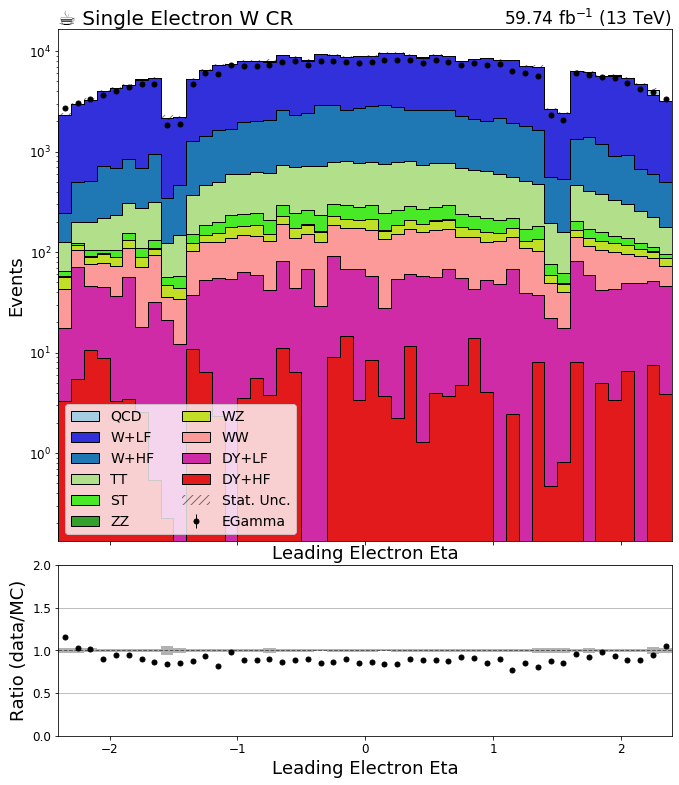

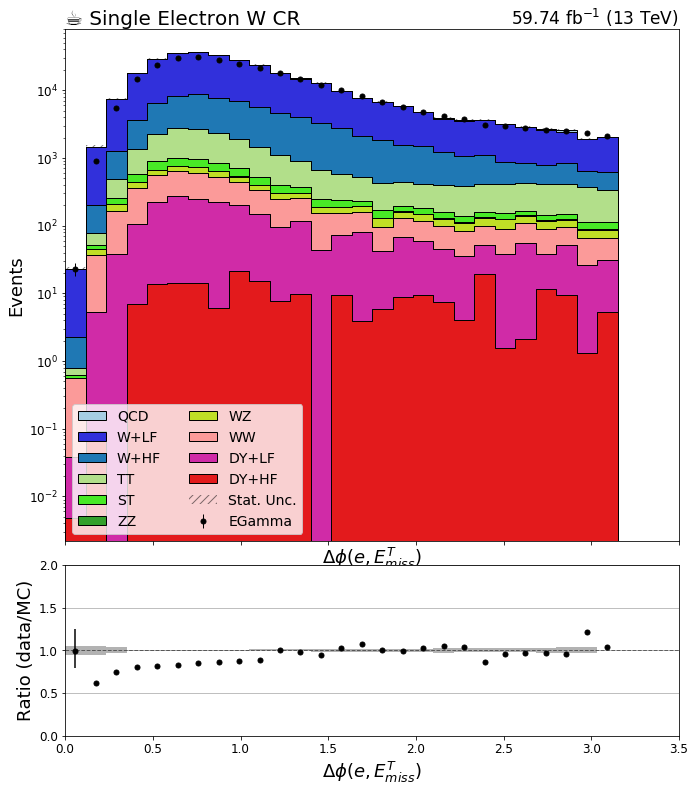

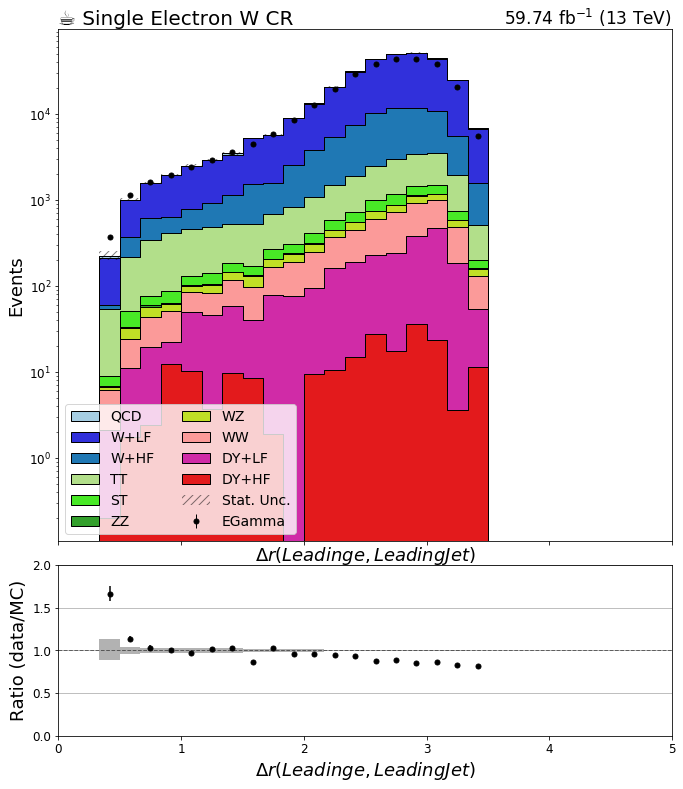

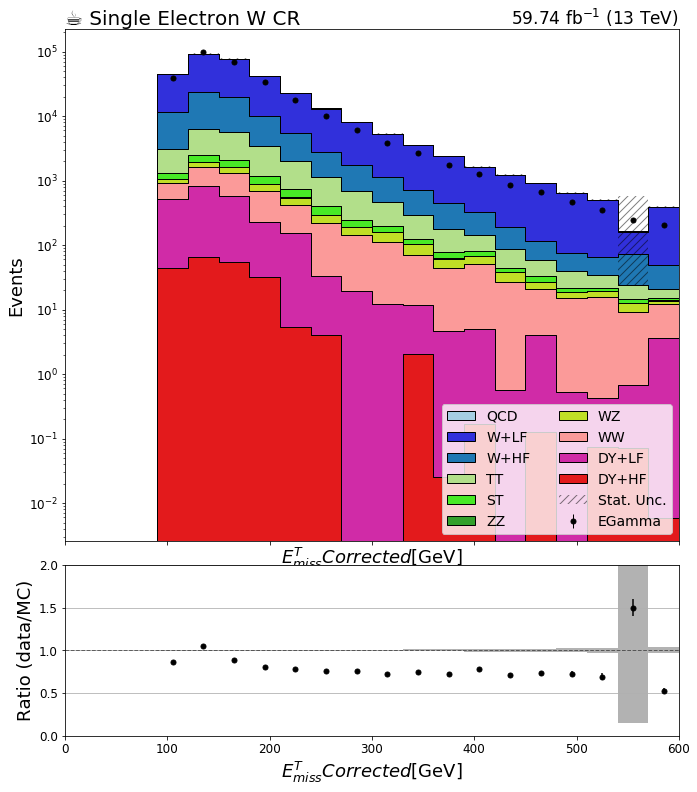

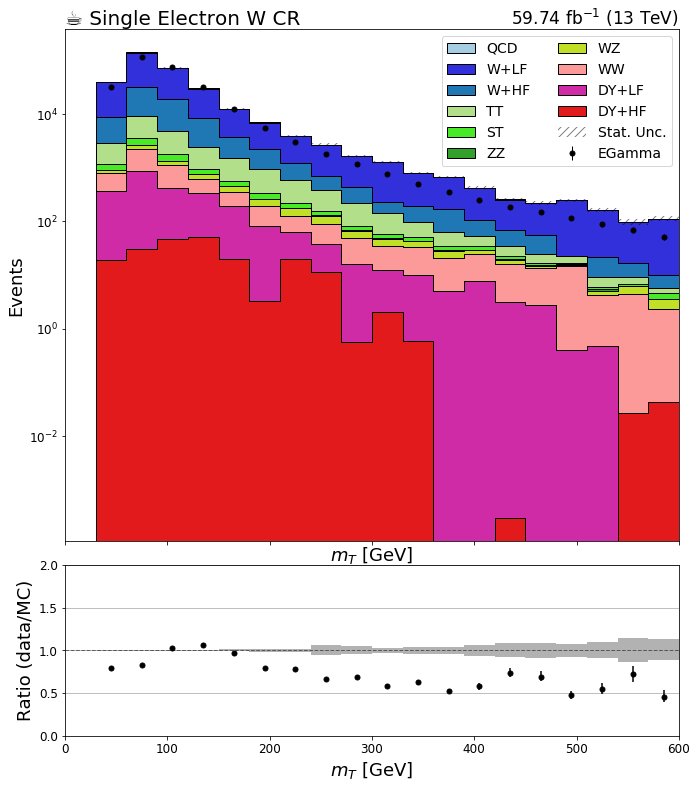

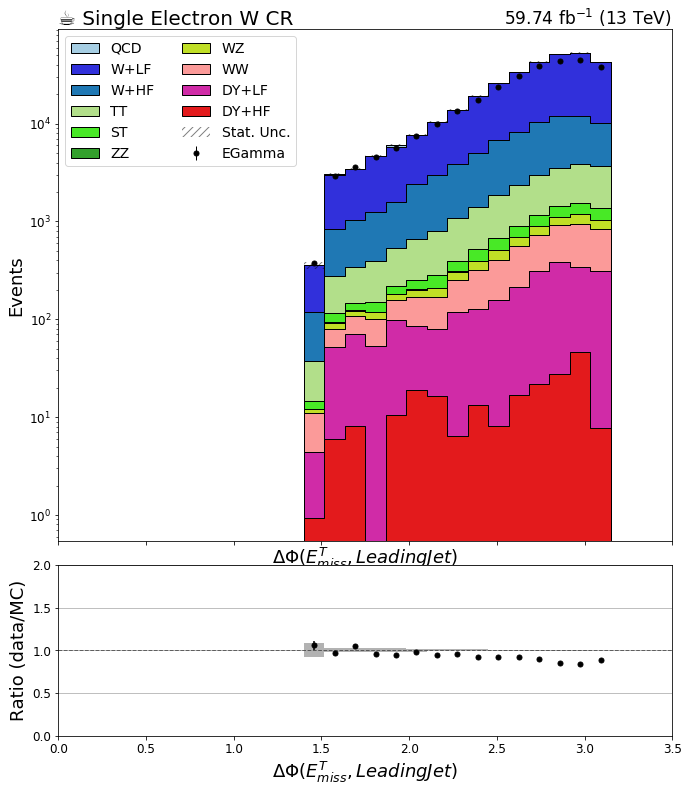

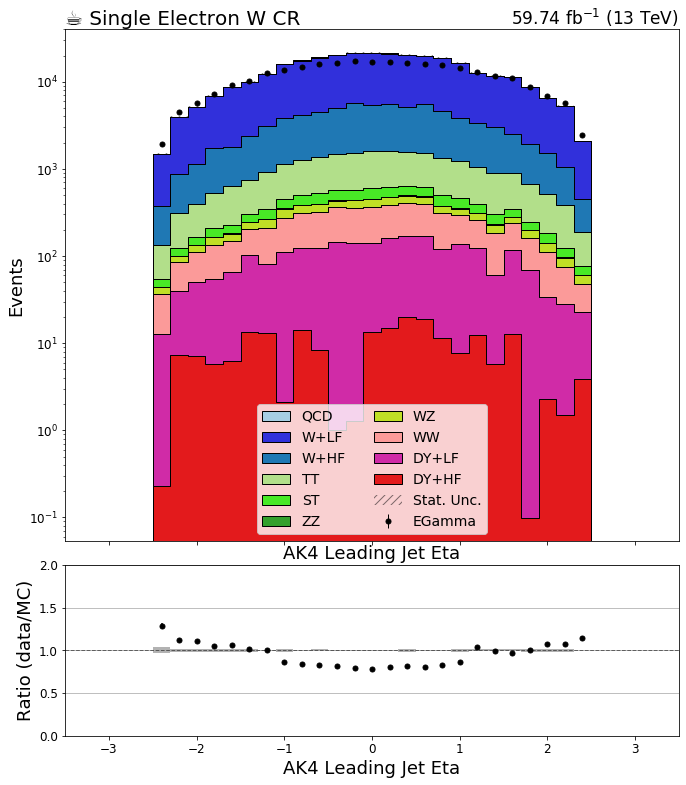

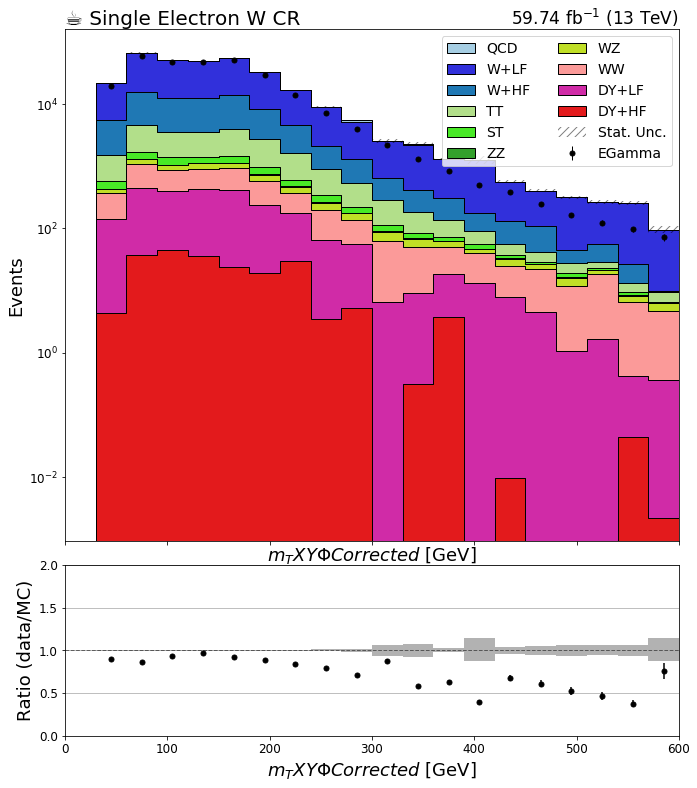

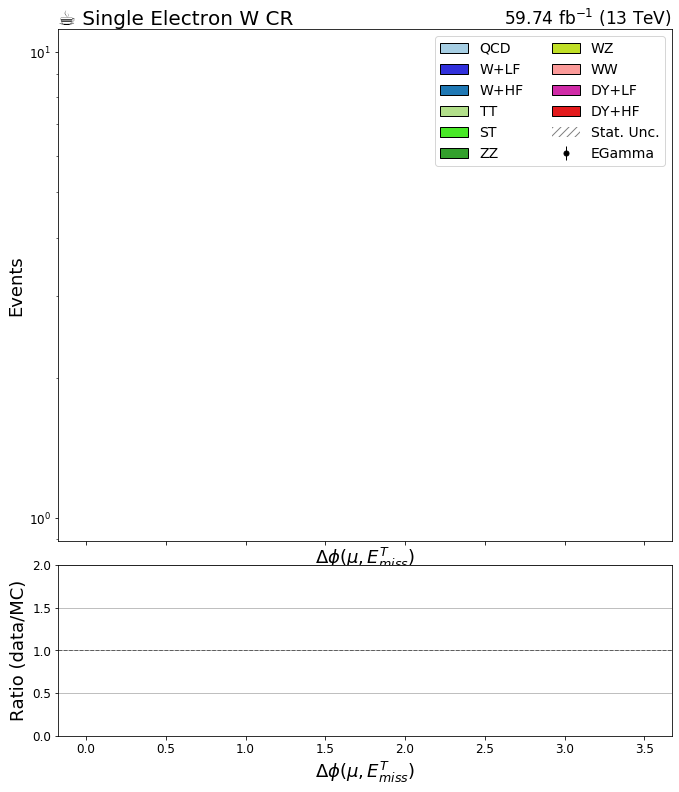

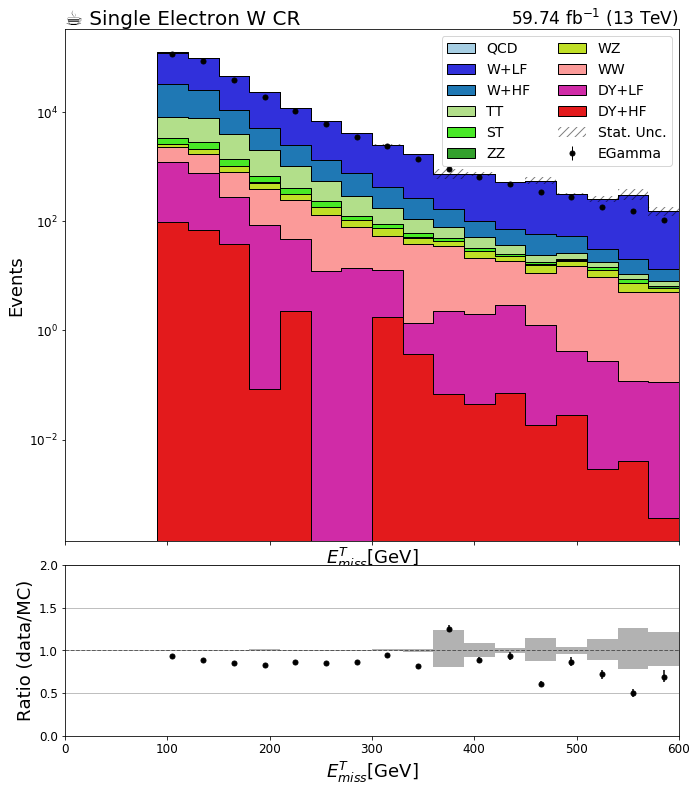

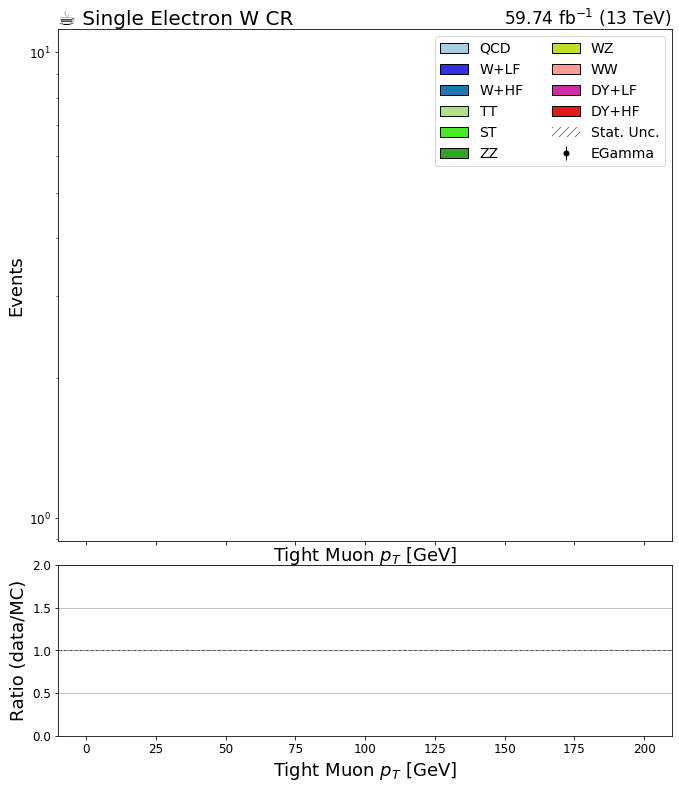

In [7]:
#http://colorbrewer2.org/#type=qualitative&scheme=Paired&n=6 : colors
from cycler import cycler
year = '2018'
region = 'wjete'
sys = 'nominal'



if not os.path.exists('../plots'):
    os.makedirs('../plots')
R = {}
R['sre'] = 'Signal Region Electron'
R['srm'] = 'Signal Region Muon'
R['wjetm'] = 'Single Muon W CR'
R['ttbarm'] = 'Single Muon Top CR'
R['wjete'] = 'Single Electron W CR'
R['ttbare'] = 'Single Electron Top CR'
# R['zecr'] = 'Double Electron Z CR'
# R['zmcr'] = 'Double Muon Z CR'
# R['gcr'] = 'Single Photon CR'

for key in bkg_hists.keys():
    if key=='sumw': continue
    if key=='template': continue
    if key=='cutflow': continue
    if key=='W_gen_pT':continue
    if key=='Z_gen_pT': continue
    #if key!='fjmass': continue
    for j in bkg_hists[key].identifiers('region'):
        if not (str(j) == region): continue
        plt.rcParams.update({'figure.max_open_warning': 0,'font.size': 14, 'axes.titlesize': 18, 'axes.labelsize': 18, 'xtick.labelsize': 12, 'ytick.labelsize': 12})
        fill_opts = {'edgecolor': (0,0,0,0.3), 'alpha': 1}
        error_opts = {'label':'Stat. Unc.', 'hatch':'///', 'facecolor':'none', 'edgecolor':(0,0,0,.5), 'linewidth': 0}
        nostack_fill_opts = {'alpha': 0.2, 'label': '_nolabel_'}
        data_err_opts = {'linestyle':'None', 'marker': '.', 'markersize': 10., 'color':'k'}#, 'elinewidth': 1, 'emarker': '_'}
        #colors = ['#a6cee3','#1f78b4','#b2df8a','#33a02c','#fb9a99','#e31a1c']
        colors = ['#a6cee3', '#3130db', '#1f78b4', '#b2df8a', '#48e926', '#33a02c', '#c0df26',
                  '#fb9a99', '#d02ba7', '#e31a1c', '#fdbf6f', '#ff7f00', '#cab2d6', '#c64bc4',
                  '#6a3d9a', '#a9ce26', '#ffff99', '#b15928', '#edcc43']


        fig, (ax, rax) = plt.subplots(2, 1, figsize=(11,13), gridspec_kw={"height_ratios": (3, 1)}, sharex=True)
        fig.subplots_adjust(hspace=.07)
        ax.set_prop_cycle(cycler(color=colors))
        
       
        plot.plot1d(data_hists[key].integrate('region',j).integrate('systematic')[data[year][str(j)]],            
                overlay="process",
                ax=ax,
                clear=False,
                error_opts=data_err_opts
                   )

        plot.plot1d(bkg_hists[key].integrate('region',j).integrate('systematic'),
                overlay="process",
                ax=ax,
                clear=False,
                stack=True,
                fill_opts=fill_opts,
                error_opts=error_opts
                   )
        
        plot.plotratio(data_hists[key].integrate('region',j).integrate('process',data[year][str(j)]).integrate('systematic', 'nominal'), 
                   bkg_hists[key].integrate('region',j).integrate('systematic').sum('process'),
                   ax=rax,
                   #overflow='over',
                   error_opts=data_err_opts,
                   denom_fill_opts={},
                   guide_opts={},
                   unc='num'
                   )
        
        rax.set_ylabel('Ratio (data/MC)')
        rax.set_ylim(0.0,2.0)
        rax.grid(axis='y')
        
        ax._get_lines.prop_cycler = ax._get_patches_for_fill.prop_cycler
        args = {'linestyle':'--', 'linewidth': 5}
        ax.autoscale(axis='x', tight=True)
        ax.set_yscale('log')
        if(key=='dilepmass'): ax.set_xlim(50, 130)
        ax.set_ylim(.1, None)
        ax.autoscale()
        leg = ax.legend(ncol=2, loc='best')
        
        coffee = plt.text(0., 1., u"☕ "+R[str(j).split('_')[0]], fontsize=20, horizontalalignment='left', verticalalignment='bottom', transform=ax.transAxes)
        lumi = plt.text(1., 1., r"59.74 fb$^{-1}$ (13 TeV)", fontsize=17, horizontalalignment='right', verticalalignment='bottom', transform=ax.transAxes)
        os.system('mkdir -p ../plots/leptonic'+year+'/'+str(j)+'/')
        plot_path = os.path.abspath('../plots/leptonic'+year+'/'+str(j)+'/') 
        plot_name = 'stack_'+key+'.png'
        fig.savefig(os.path.join(plot_path, plot_name))

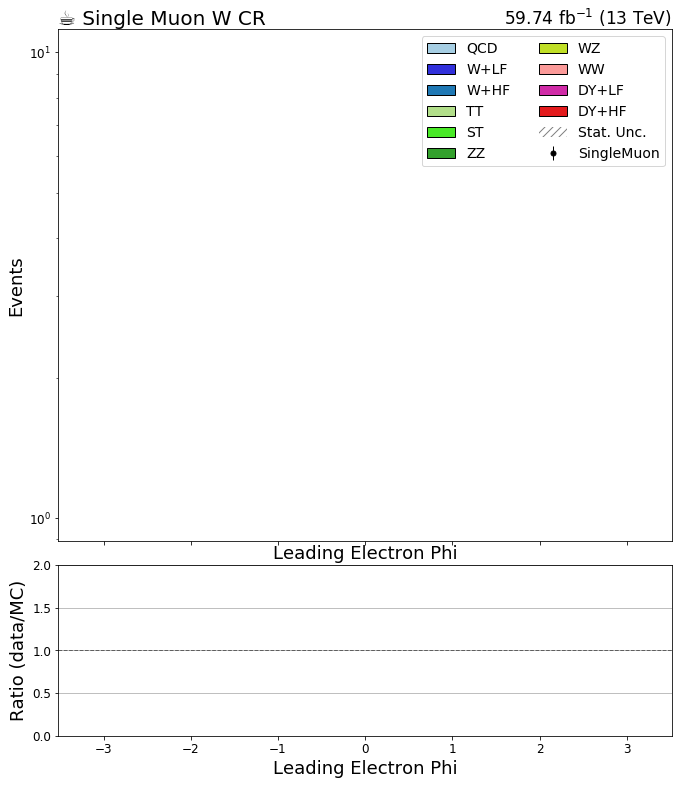

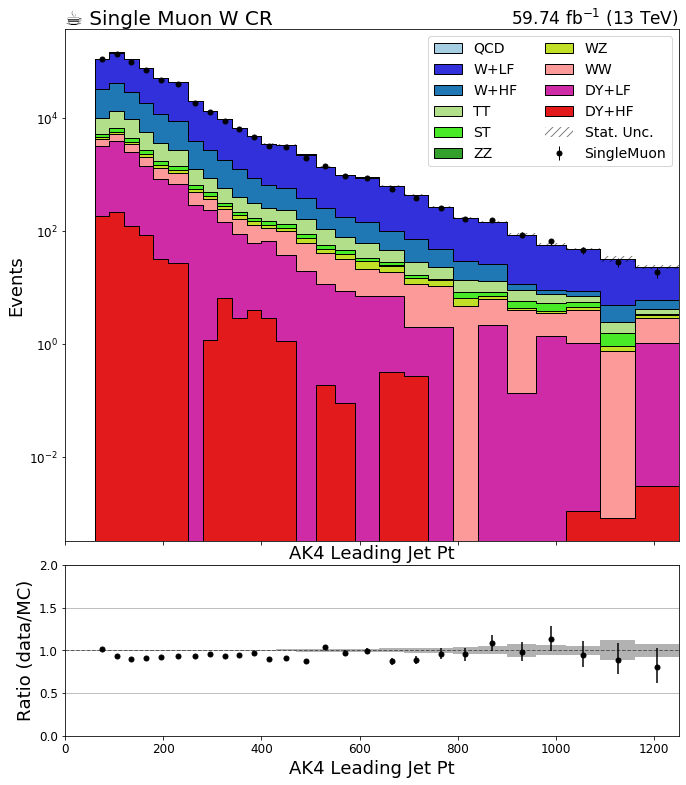

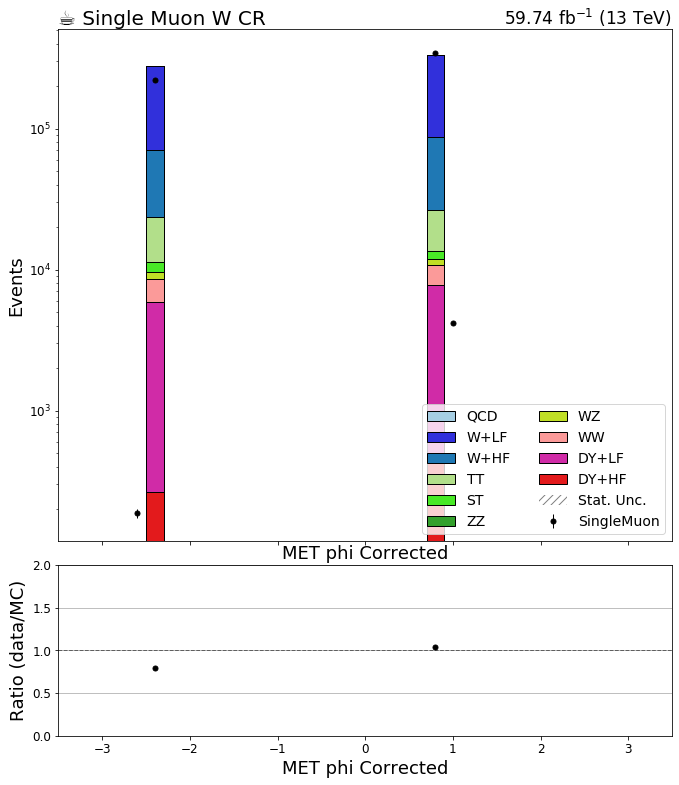

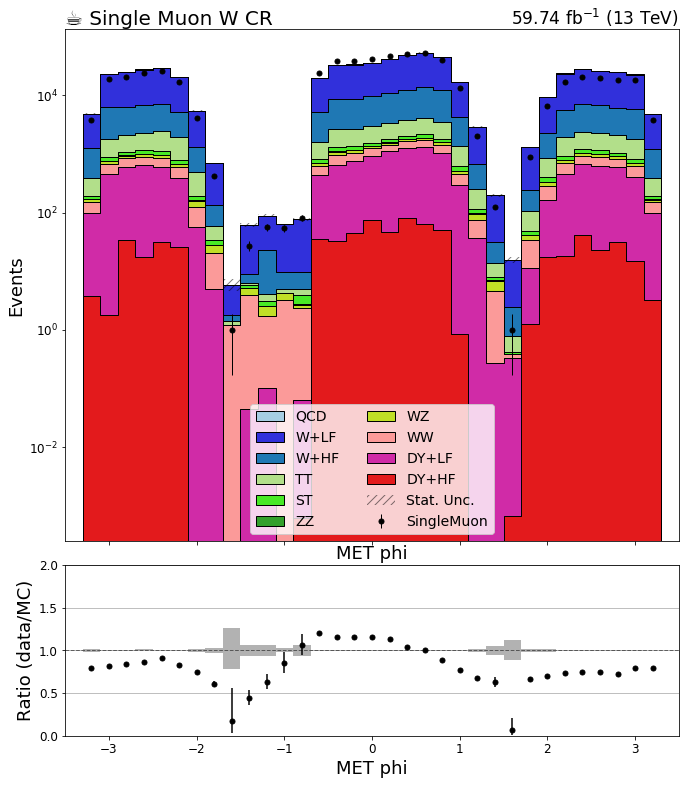

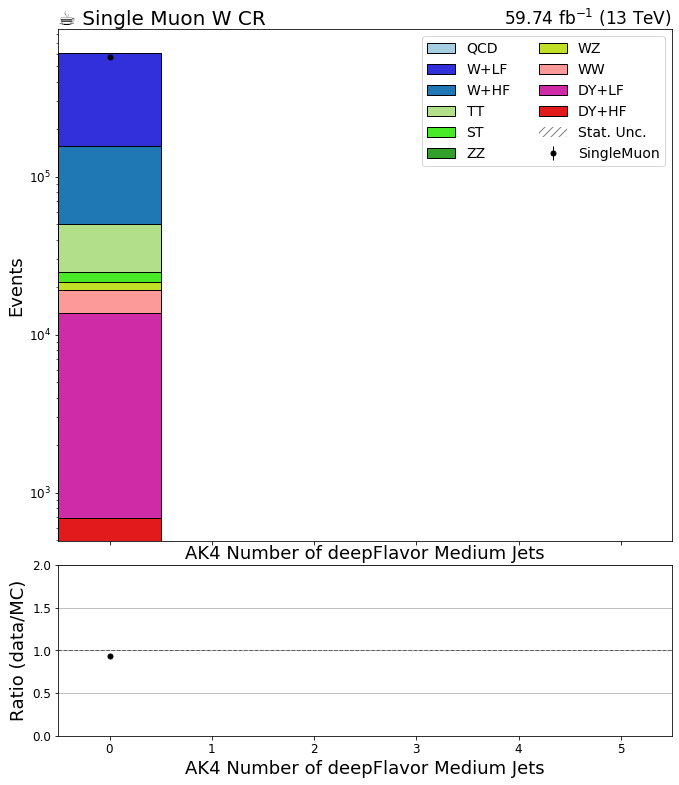

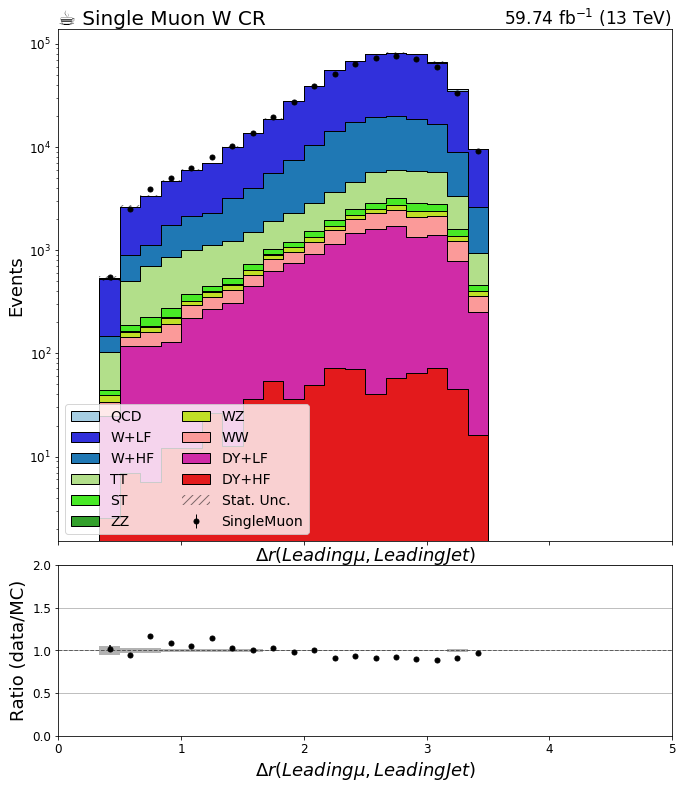

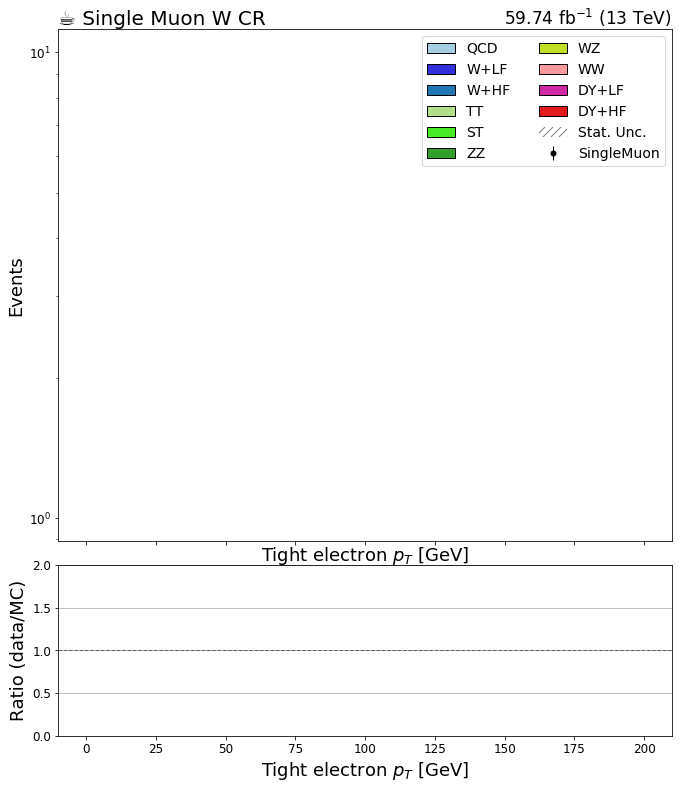

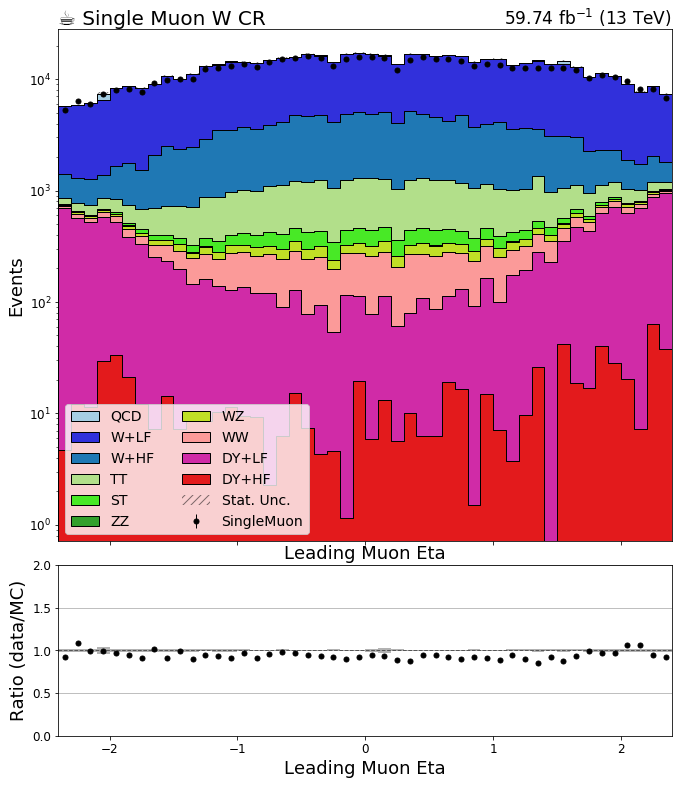

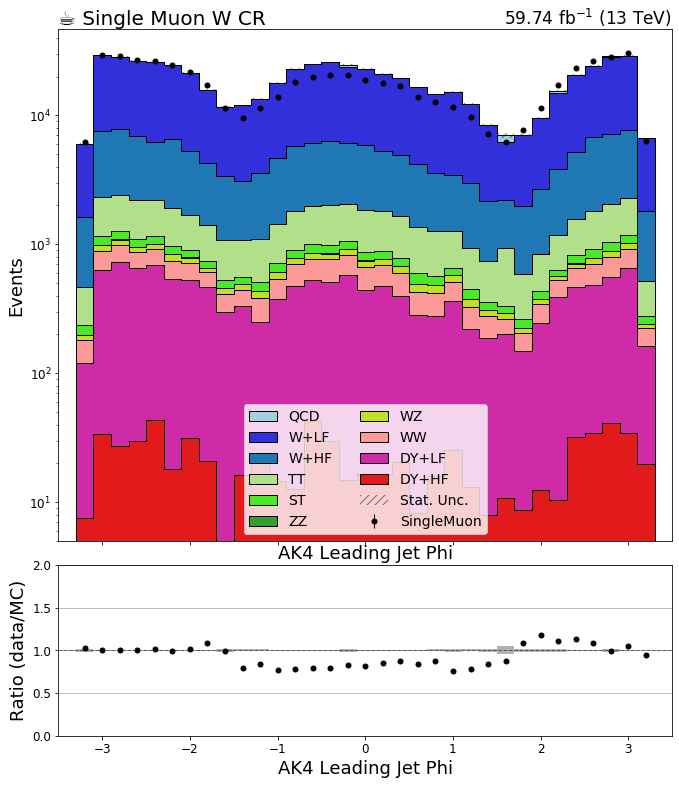

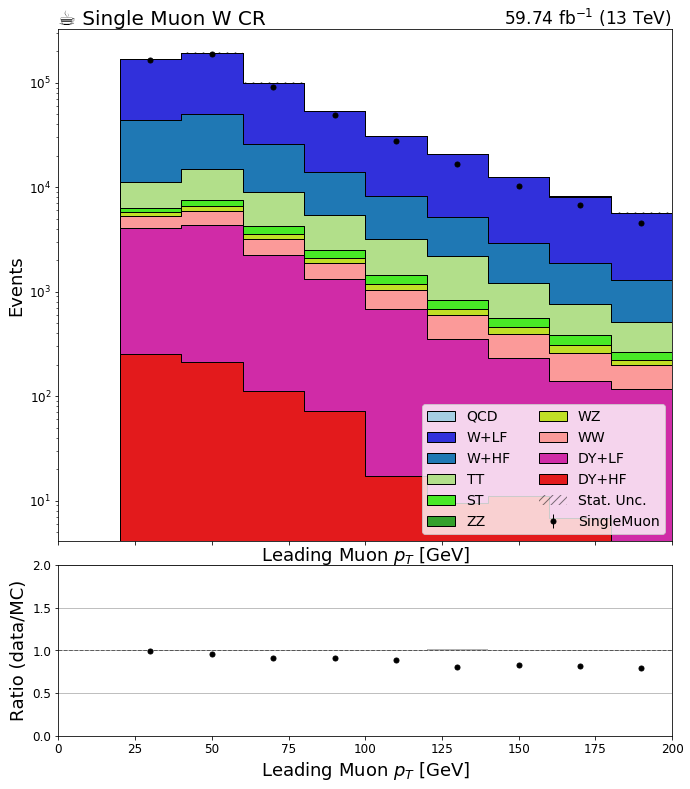

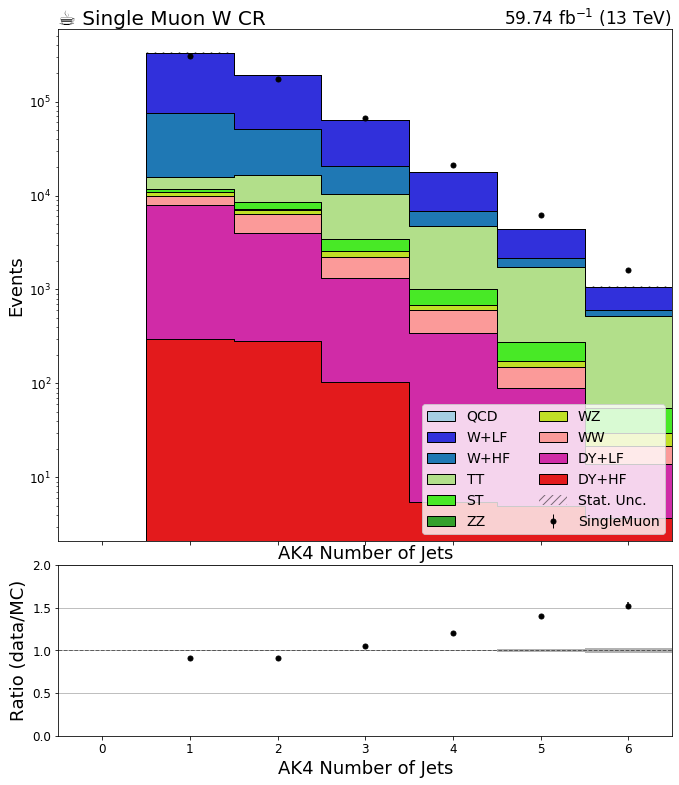

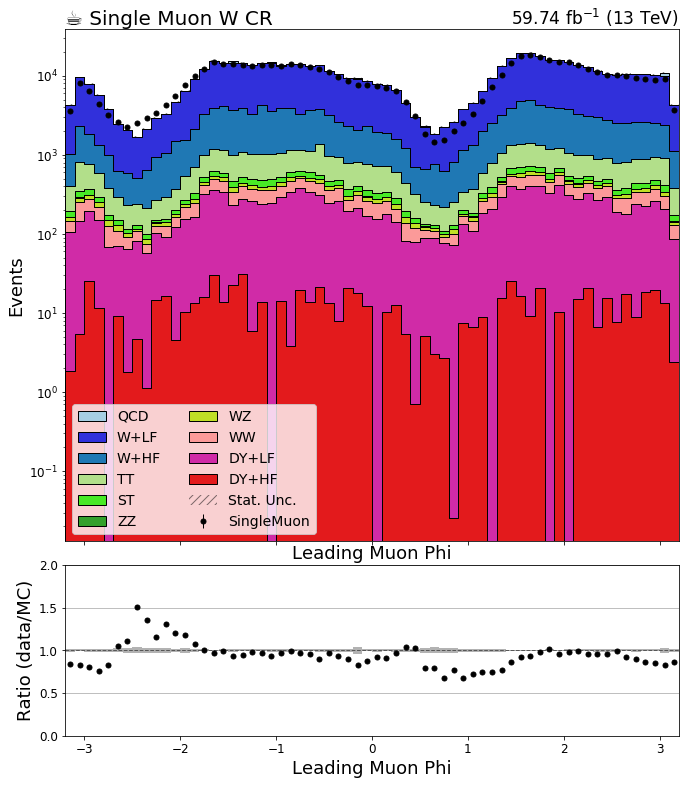

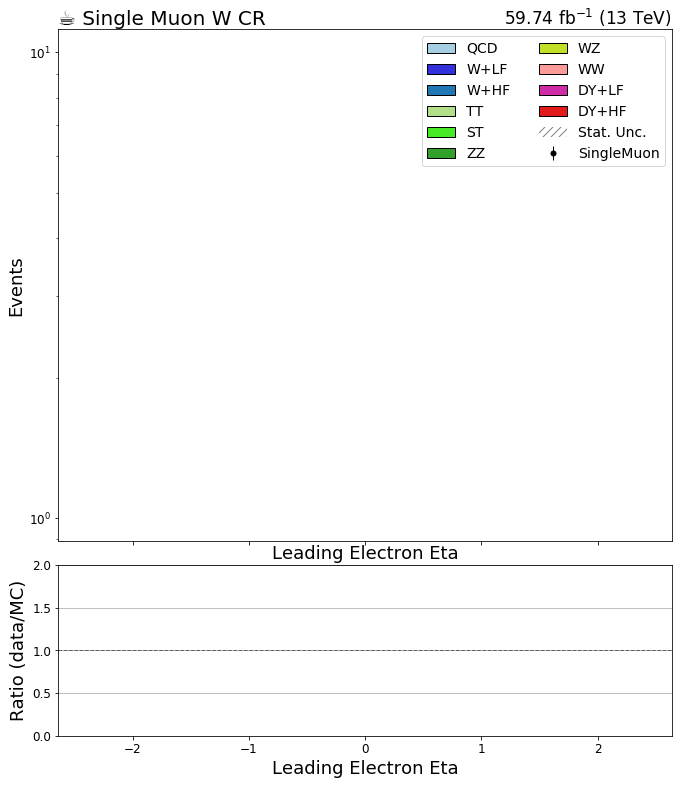

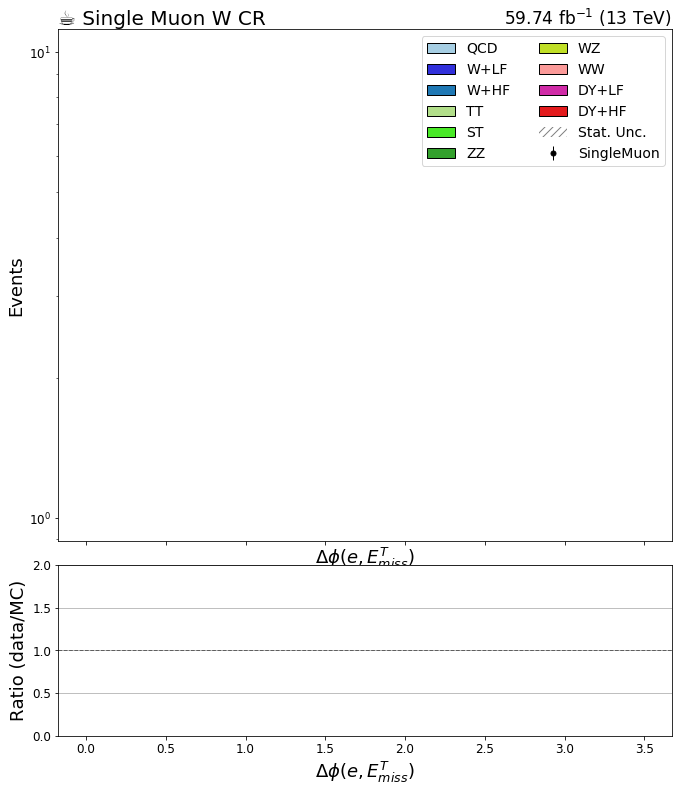

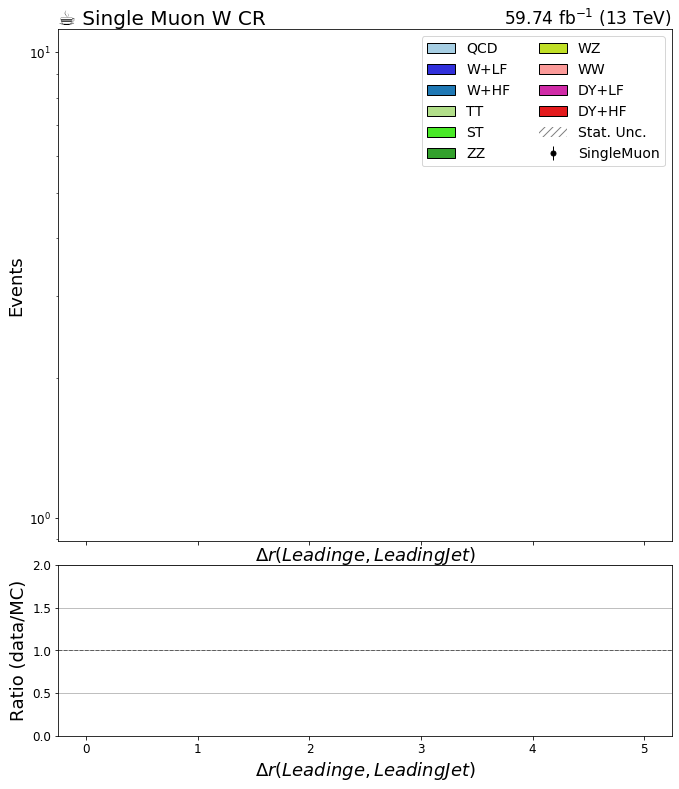

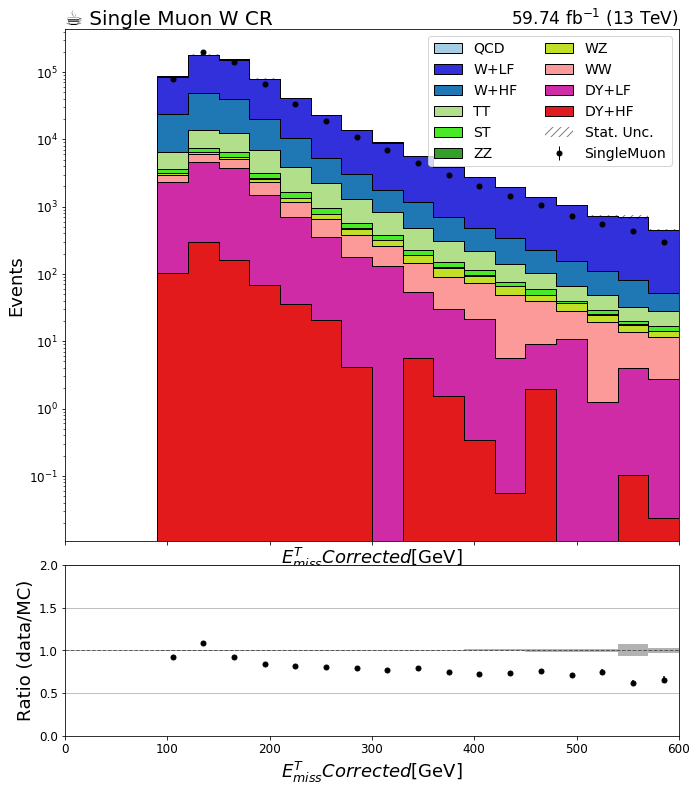

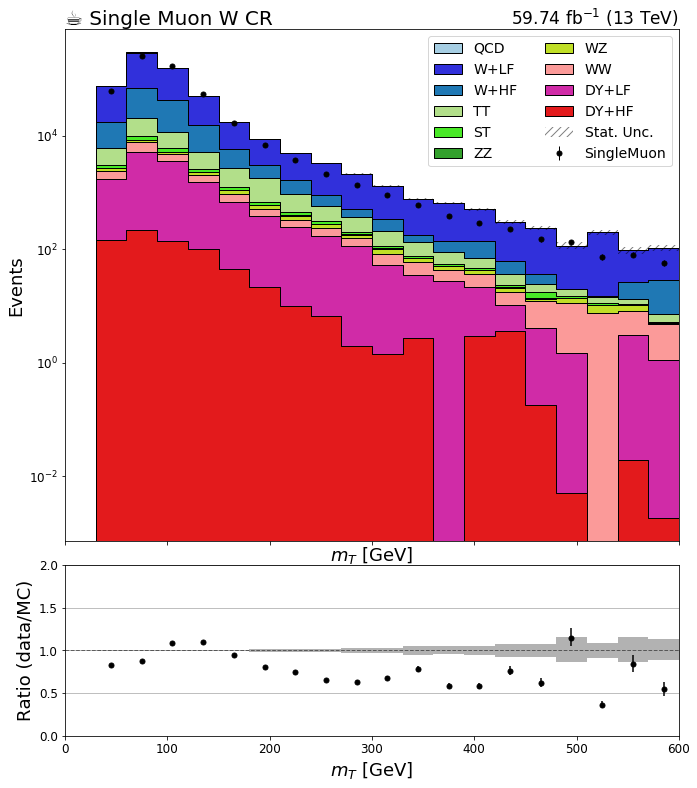

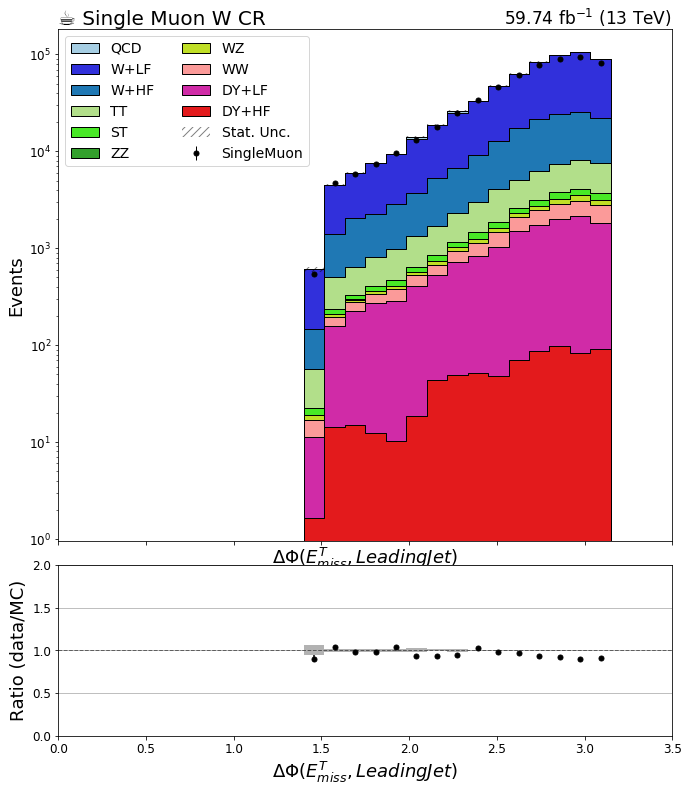

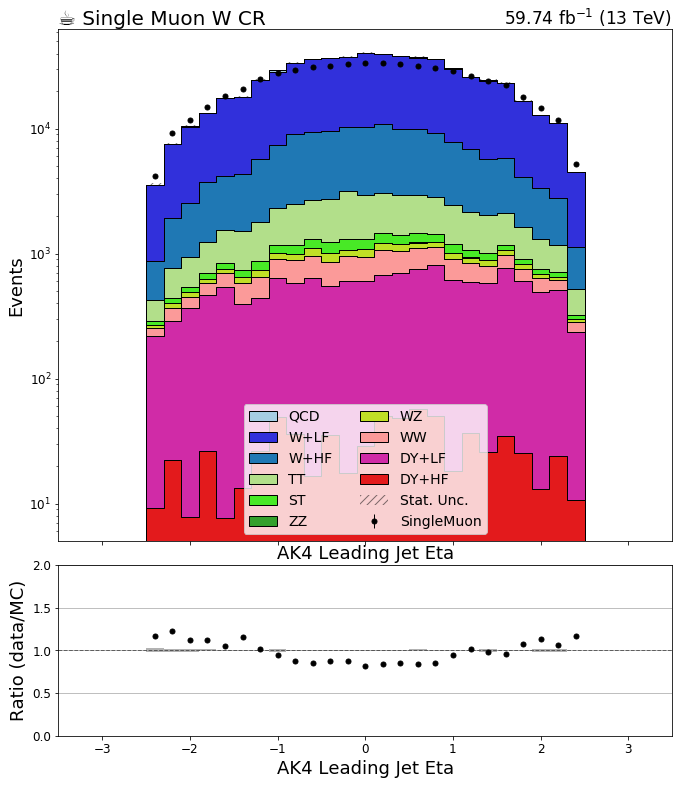

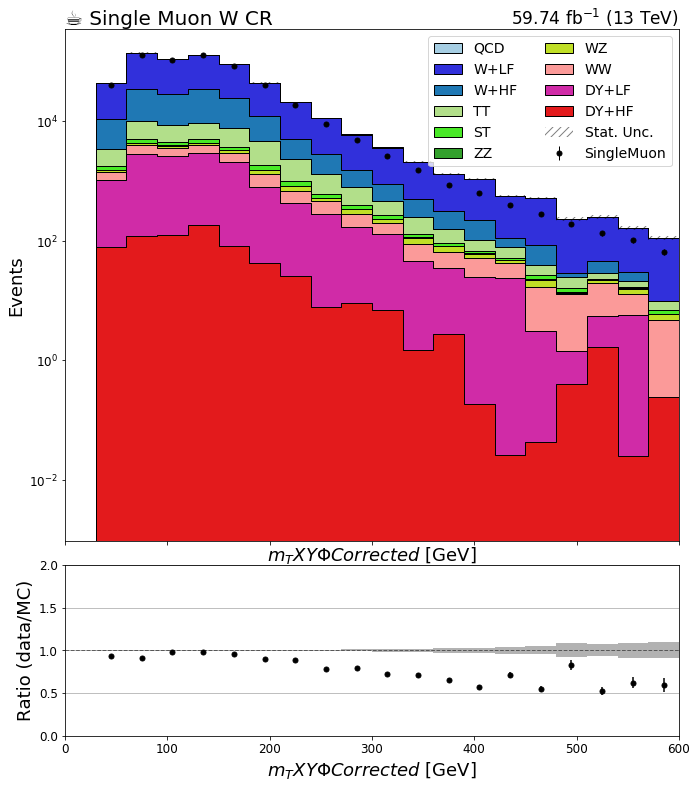

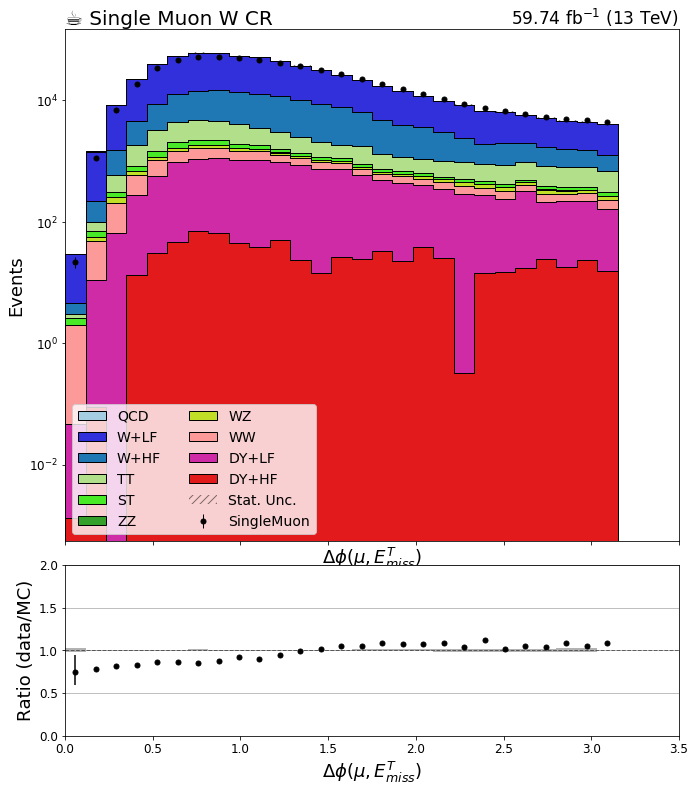

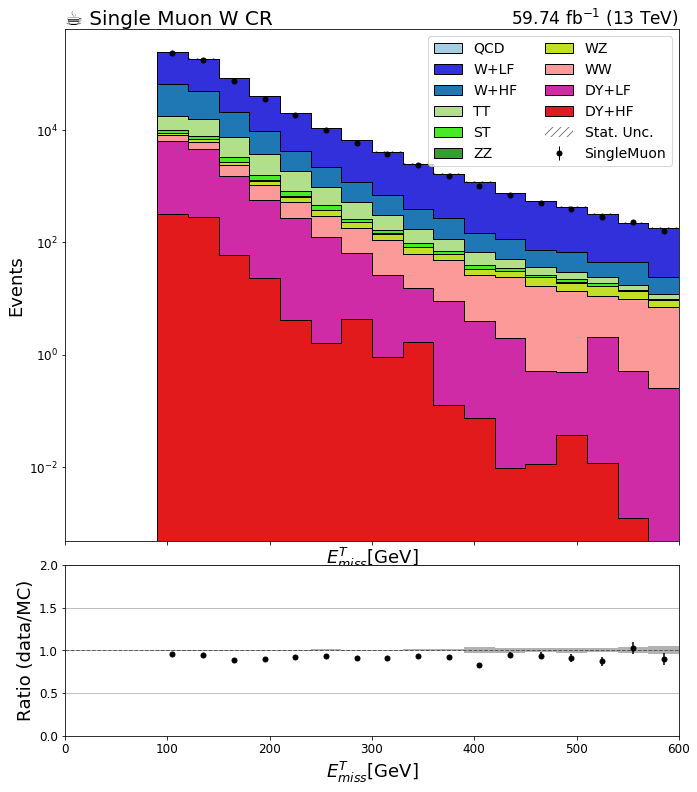

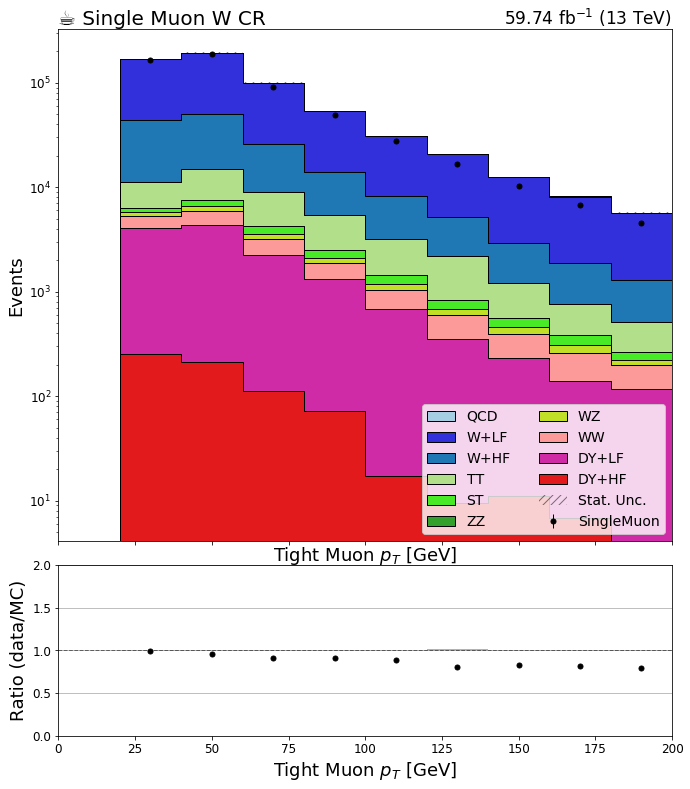

In [48]:
#http://colorbrewer2.org/#type=qualitative&scheme=Paired&n=6 : colors
from cycler import cycler
year = '2018'
region = 'wjetm'
sys = 'nominal'



if not os.path.exists('../plots'):
    os.makedirs('../plots')
R = {}
R['sre'] = 'Signal Region Electron'
R['srm'] = 'Signal Region Muon'
R['wjetm'] = 'Single Muon W CR'
R['ttbarm'] = 'Single Muon Top CR'
R['wjete'] = 'Single Electron W CR'
R['ttbare'] = 'Single Electron Top CR'
# R['zecr'] = 'Double Electron Z CR'
# R['zmcr'] = 'Double Muon Z CR'
# R['gcr'] = 'Single Photon CR'

for key in bkg_hists.keys():
    if key=='sumw': continue
    if key=='template': continue
    if key=='cutflow': continue
    if key=='W_gen_pT':continue
    if key=='Z_gen_pT': continue
    #if key!='fjmass': continue
    for j in bkg_hists[key].identifiers('region'):
        if not (str(j) == region): continue
        plt.rcParams.update({'figure.max_open_warning': 0,'font.size': 14, 'axes.titlesize': 18, 'axes.labelsize': 18, 'xtick.labelsize': 12, 'ytick.labelsize': 12})
        fill_opts = {'edgecolor': (0,0,0,0.3), 'alpha': 1}
        error_opts = {'label':'Stat. Unc.', 'hatch':'///', 'facecolor':'none', 'edgecolor':(0,0,0,.5), 'linewidth': 0}
        nostack_fill_opts = {'alpha': 0.2, 'label': '_nolabel_'}
        data_err_opts = {'linestyle':'None', 'marker': '.', 'markersize': 10., 'color':'k'}#, 'elinewidth': 1, 'emarker': '_'}
        #colors = ['#a6cee3','#1f78b4','#b2df8a','#33a02c','#fb9a99','#e31a1c']
        colors = ['#a6cee3', '#3130db', '#1f78b4', '#b2df8a', '#48e926', '#33a02c', '#c0df26',
                  '#fb9a99', '#d02ba7', '#e31a1c', '#fdbf6f', '#ff7f00', '#cab2d6', '#c64bc4',
                  '#6a3d9a', '#a9ce26', '#ffff99', '#b15928', '#edcc43']


        fig, (ax, rax) = plt.subplots(2, 1, figsize=(11,13), gridspec_kw={"height_ratios": (3, 1)}, sharex=True)
        fig.subplots_adjust(hspace=.07)
        ax.set_prop_cycle(cycler(color=colors))
        
       
        plot.plot1d(data_hists[key].integrate('region',j).integrate('systematic', 'nominal')[data[year][str(j)]],            
                overlay="process",
                ax=ax,
                clear=False,
                error_opts=data_err_opts
                   )

        plot.plot1d(bkg_hists[key].integrate('region',j).integrate('systematic'),
                overlay="process",
                ax=ax,
                clear=False,
                stack=True,
                fill_opts=fill_opts,
                error_opts=error_opts
                   )
        
        plot.plotratio(data_hists[key].integrate('region',j).integrate('systematic').integrate('process',data[year][str(j)]), 
                   bkg_hists[key].integrate('region',j).integrate('systematic').sum('process'),
                   ax=rax,
                   #overflow='over',
                   error_opts=data_err_opts,
                   denom_fill_opts={},
                   guide_opts={},
                   unc='num'
                   )
        
        rax.set_ylabel('Ratio (data/MC)')
        rax.set_ylim(0.0,2.0)
        rax.grid(axis='y')
        
        ax._get_lines.prop_cycler = ax._get_patches_for_fill.prop_cycler
        args = {'linestyle':'--', 'linewidth': 5}
        ax.autoscale(axis='x', tight=True)
        ax.set_yscale('log')
        if(key=='dilepmass'): ax.set_xlim(50, 130)
        ax.set_ylim(.1, None)
        ax.autoscale()
        leg = ax.legend(ncol=2, loc='best')
        
        coffee = plt.text(0., 1., u"☕ "+R[str(j).split('_')[0]], fontsize=20, horizontalalignment='left', verticalalignment='bottom', transform=ax.transAxes)
        lumi = plt.text(1., 1., r"59.74 fb$^{-1}$ (13 TeV)", fontsize=17, horizontalalignment='right', verticalalignment='bottom', transform=ax.transAxes)
        os.system('mkdir -p ../plots/leptonic'+year+'/'+str(j)+'/')
        plot_path = os.path.abspath('../plots/leptonic'+year+'/'+str(j)+'/') 
        plot_name = 'stack_'+key+'.png'
        fig.savefig(os.path.join(plot_path, plot_name))

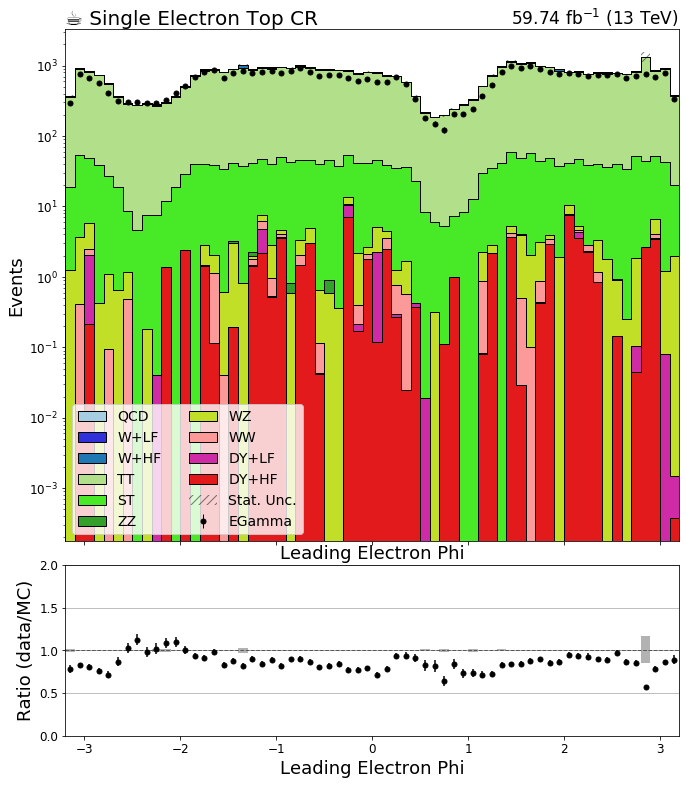

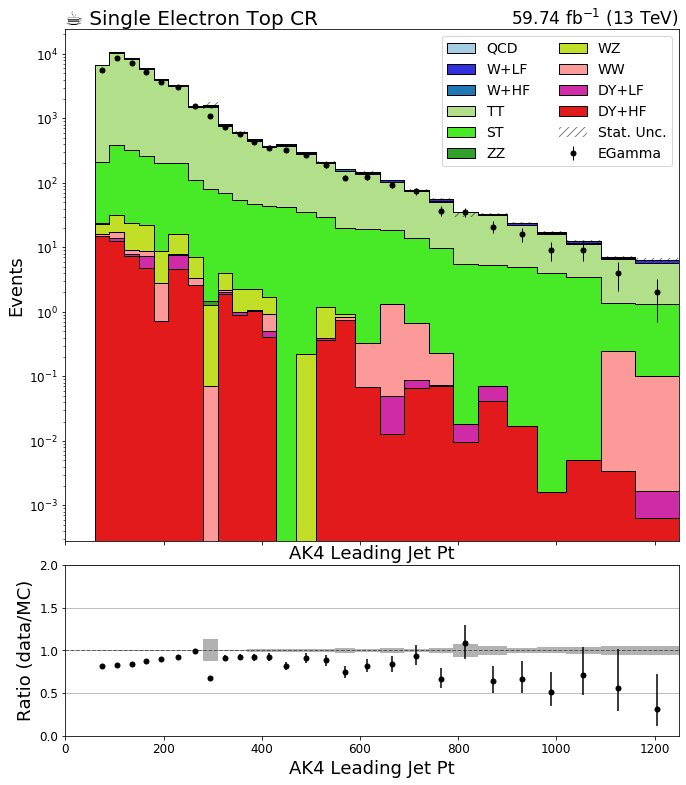

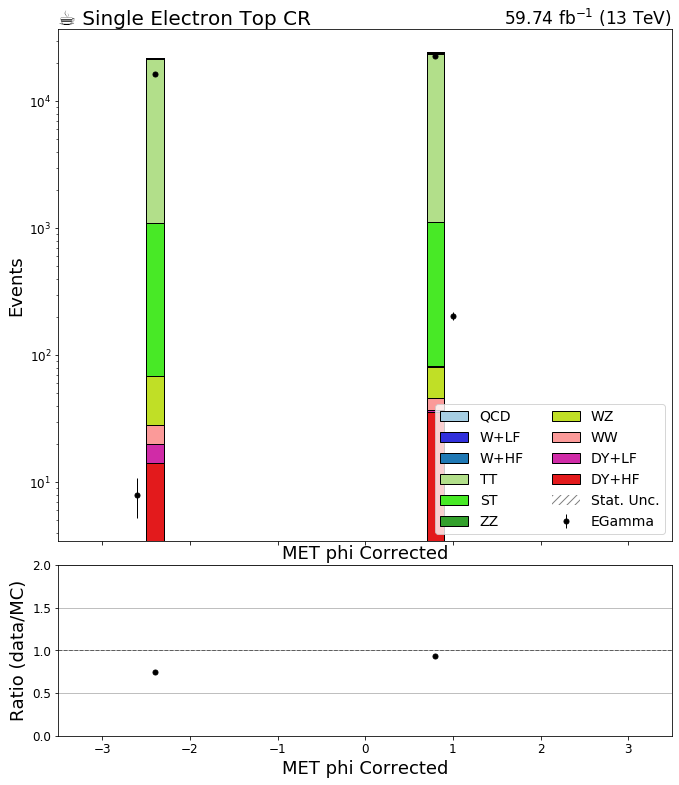

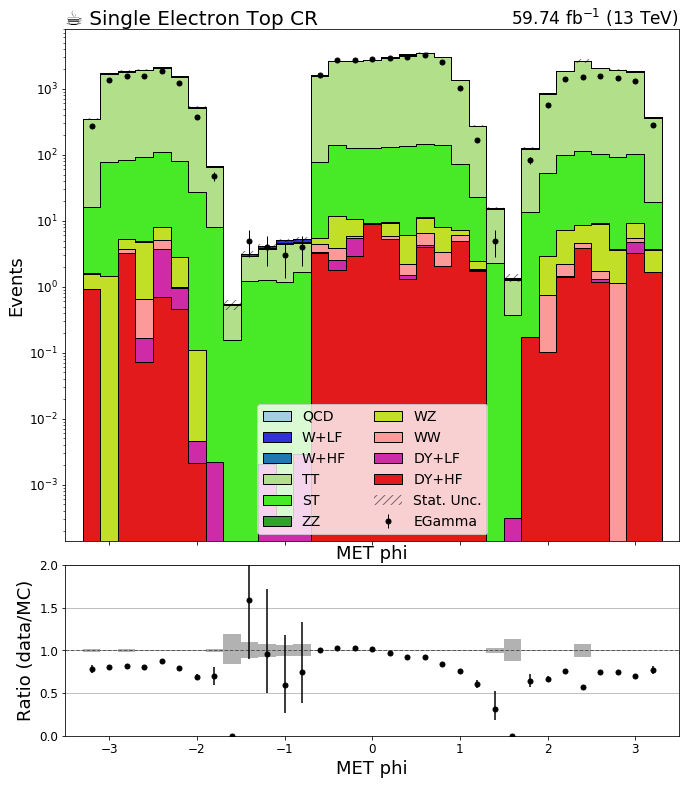

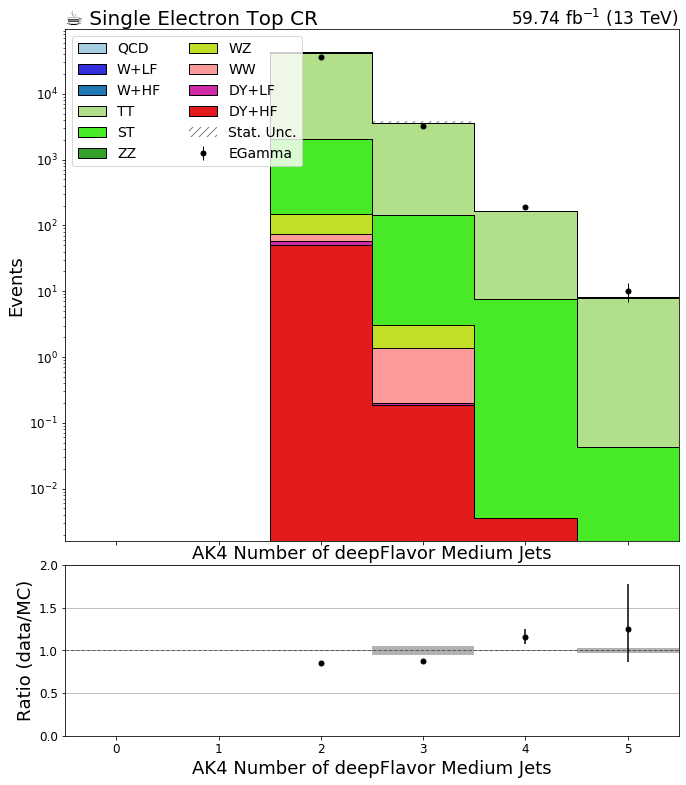

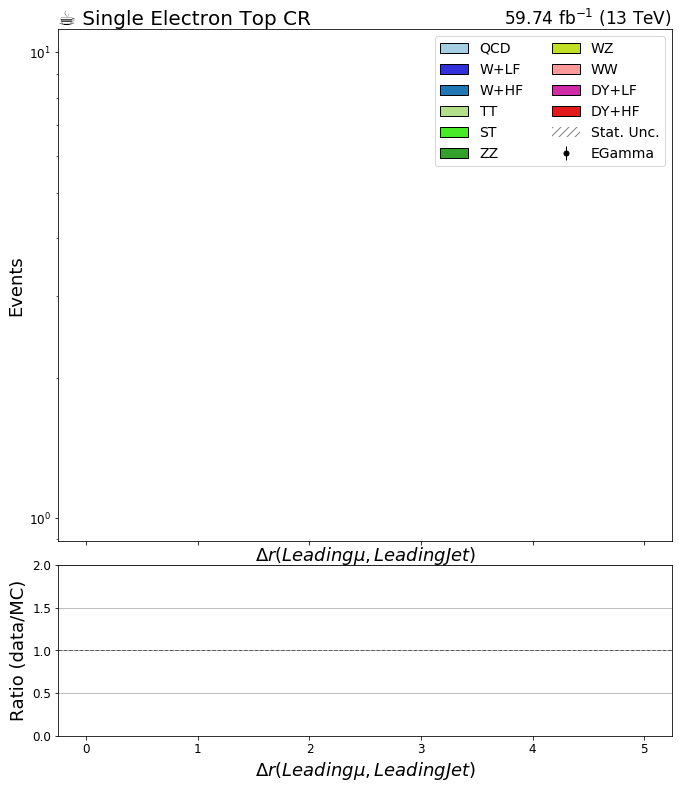

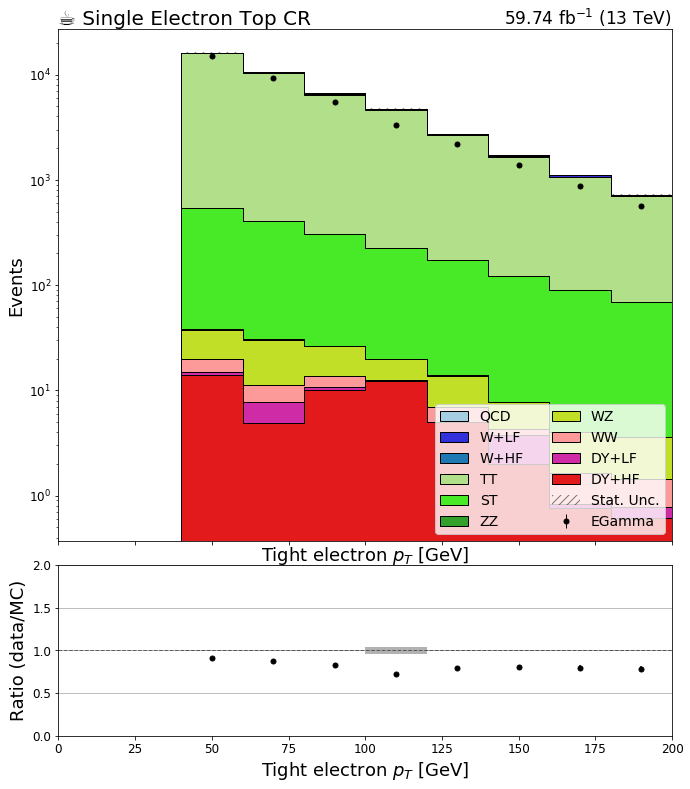

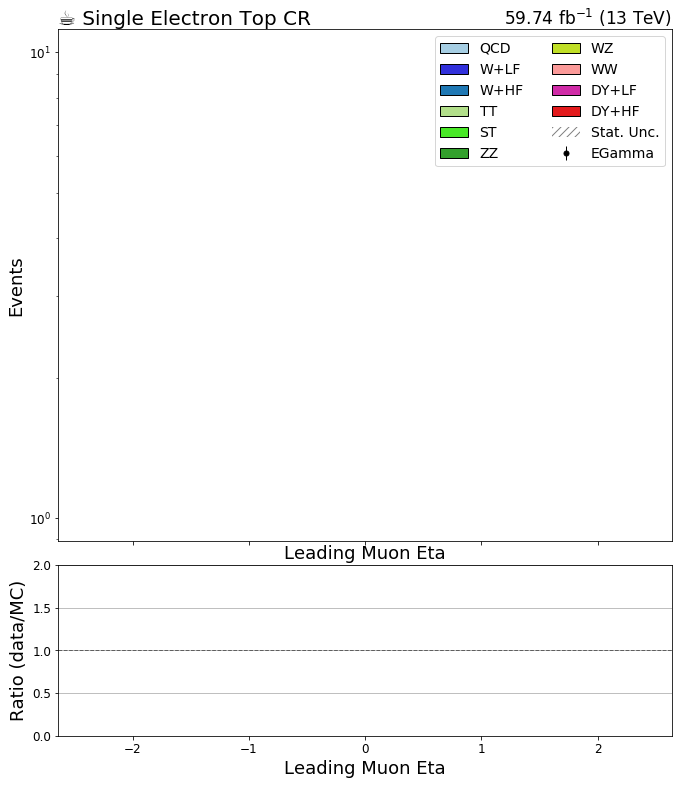

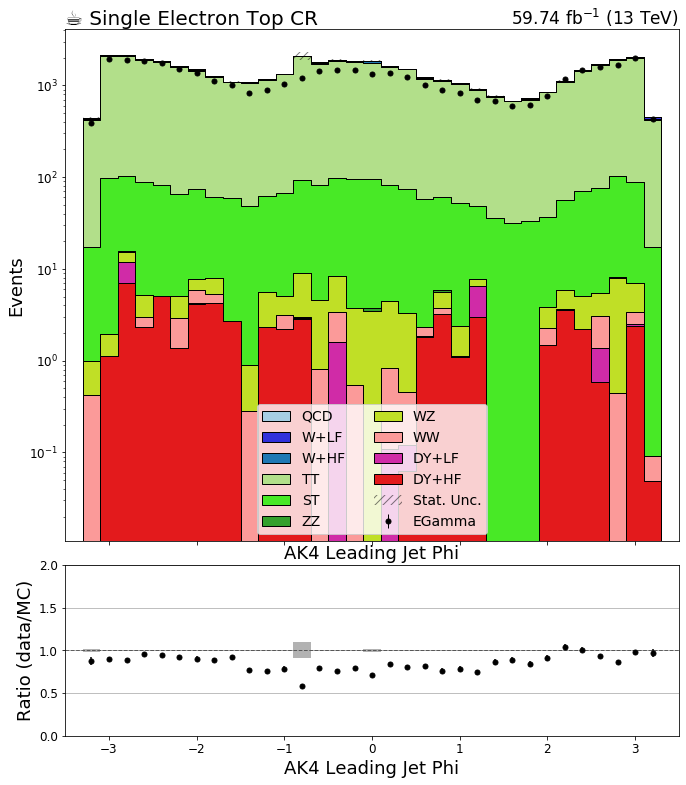

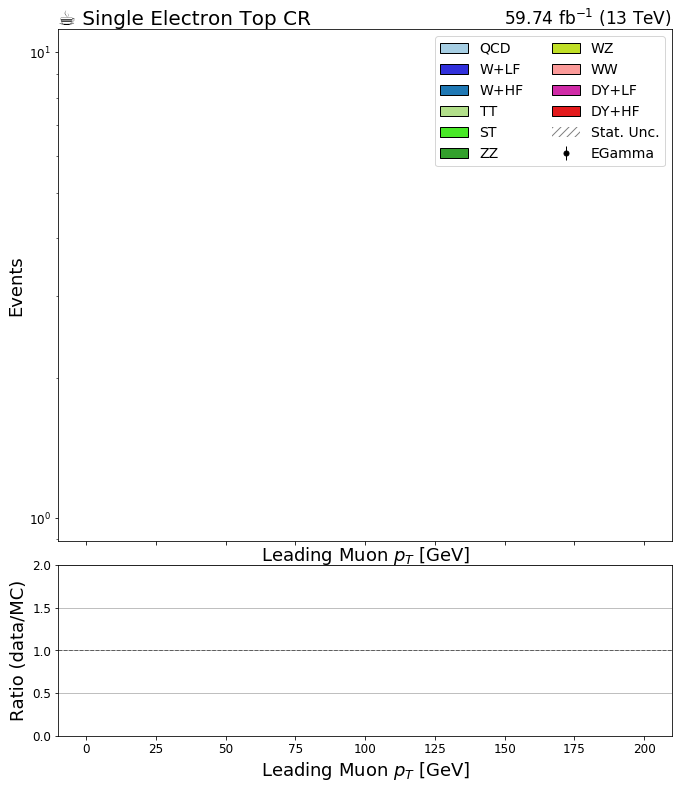

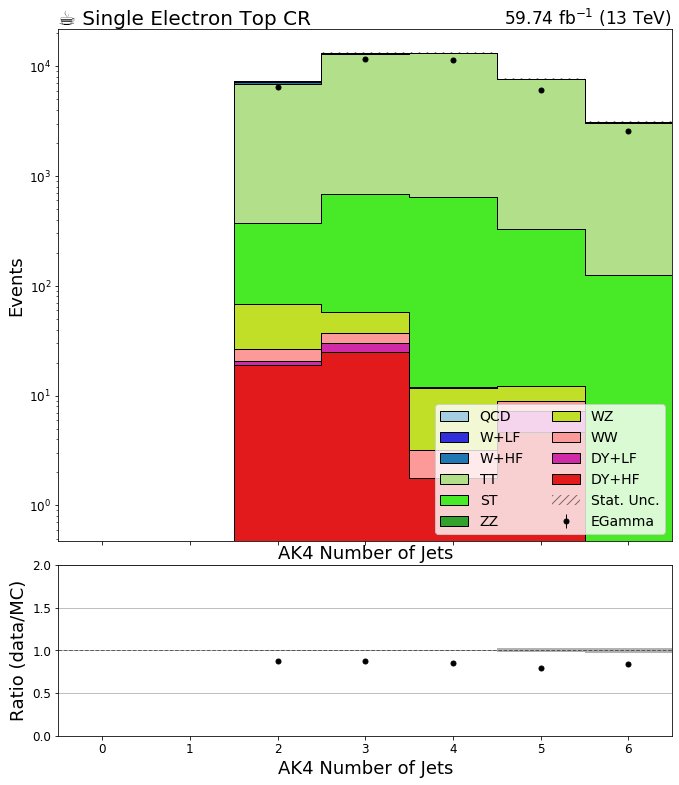

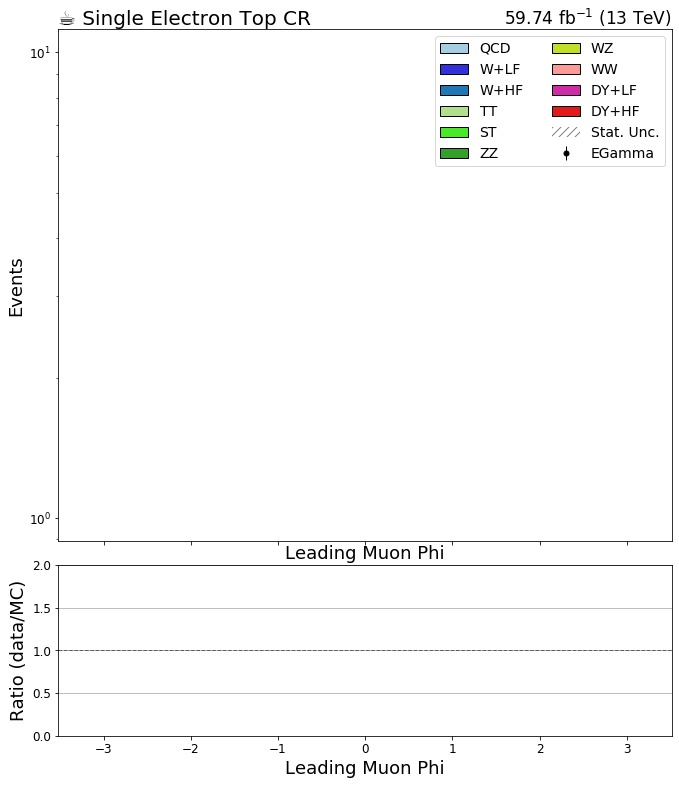

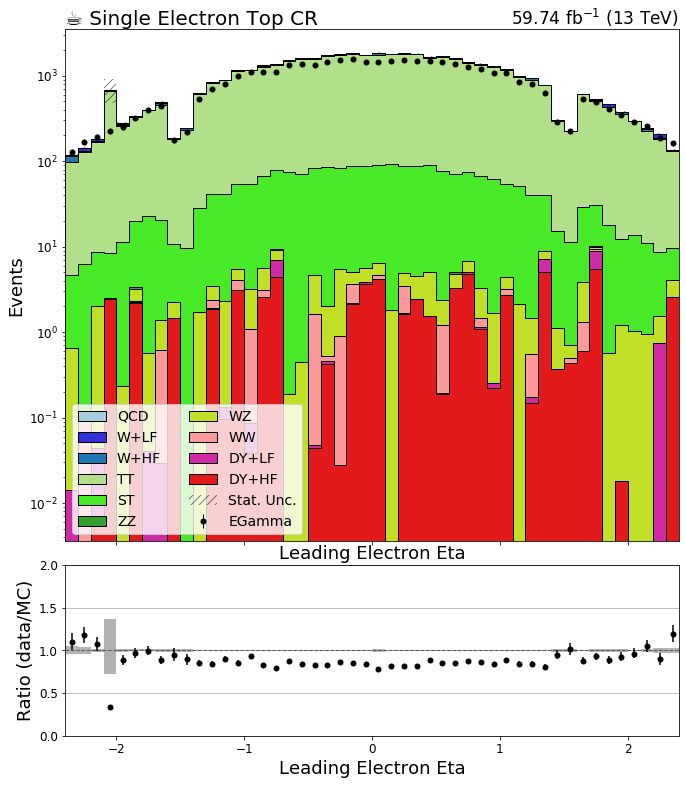

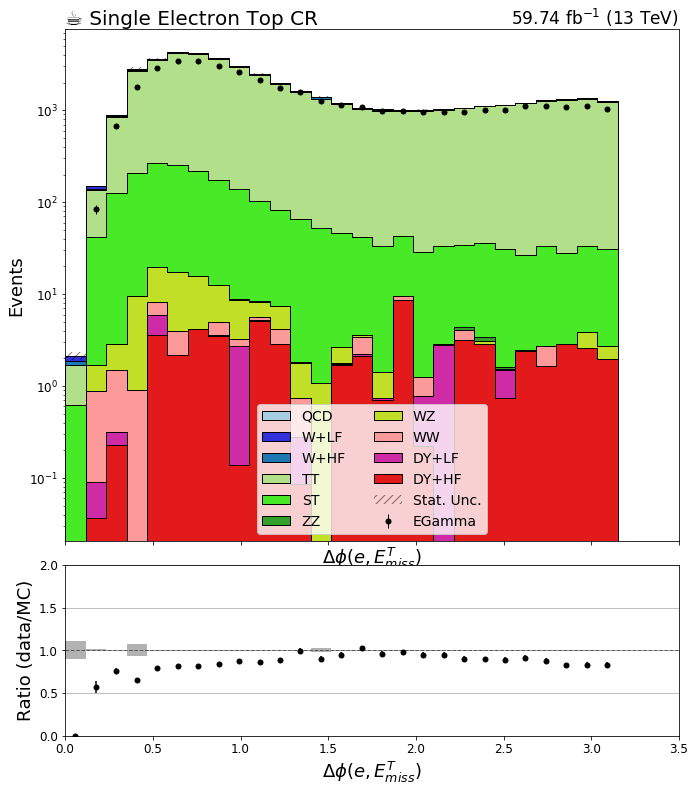

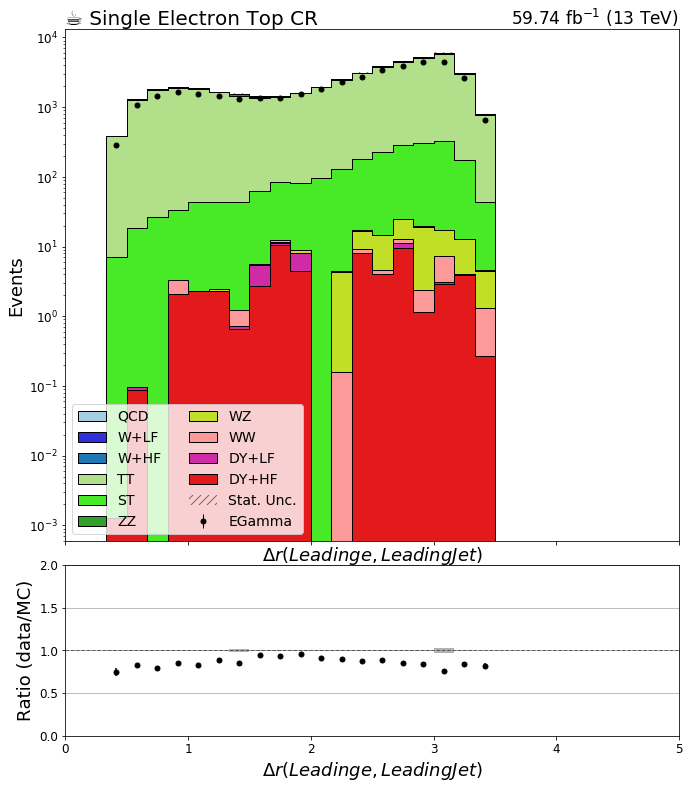

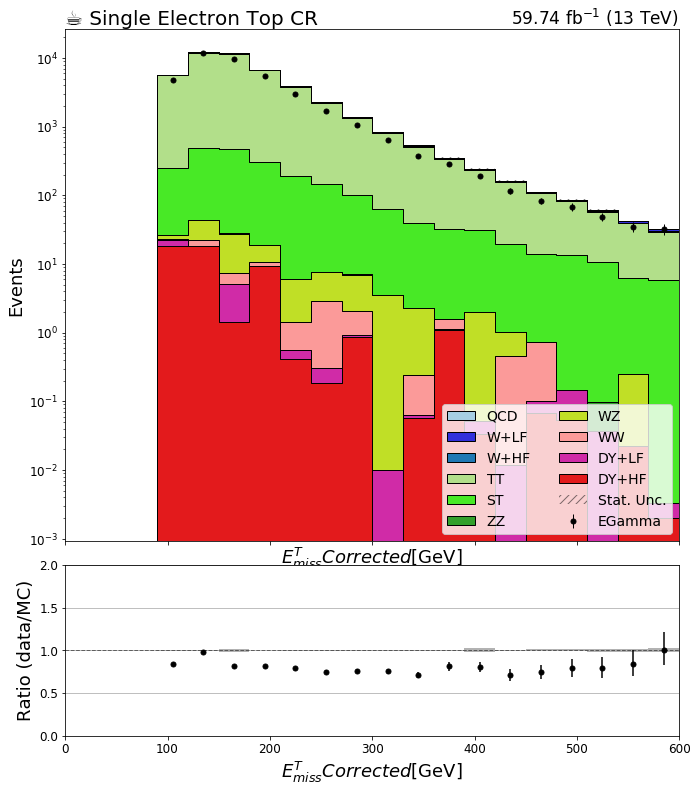

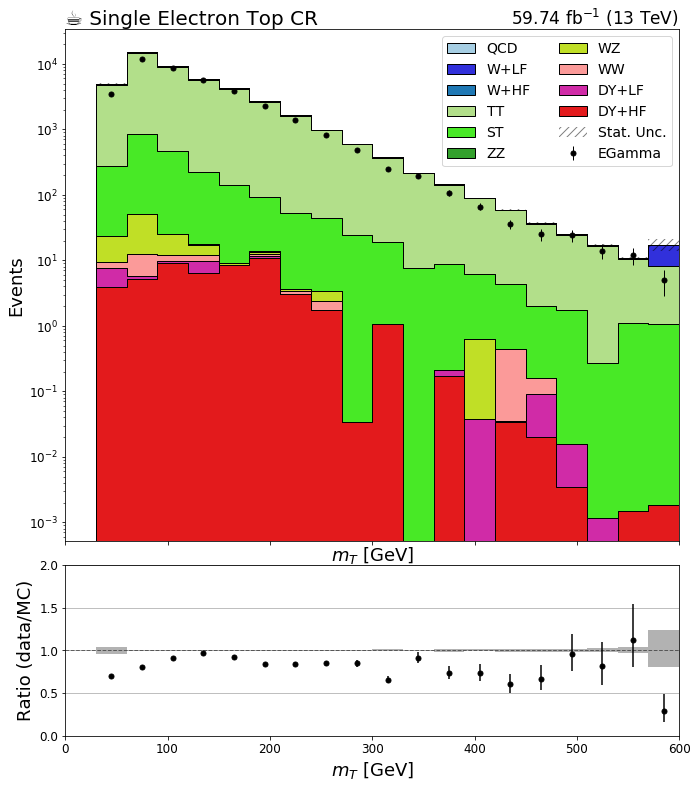

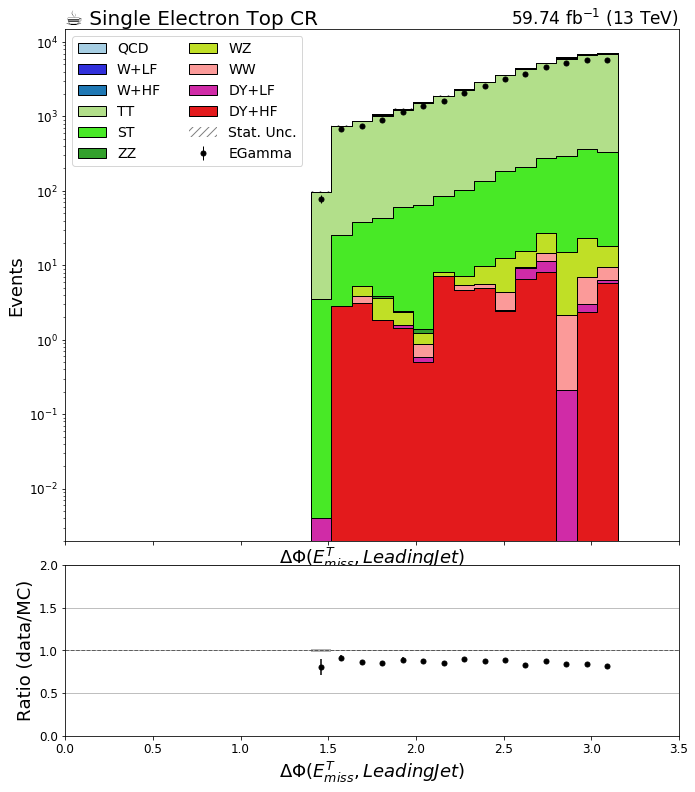

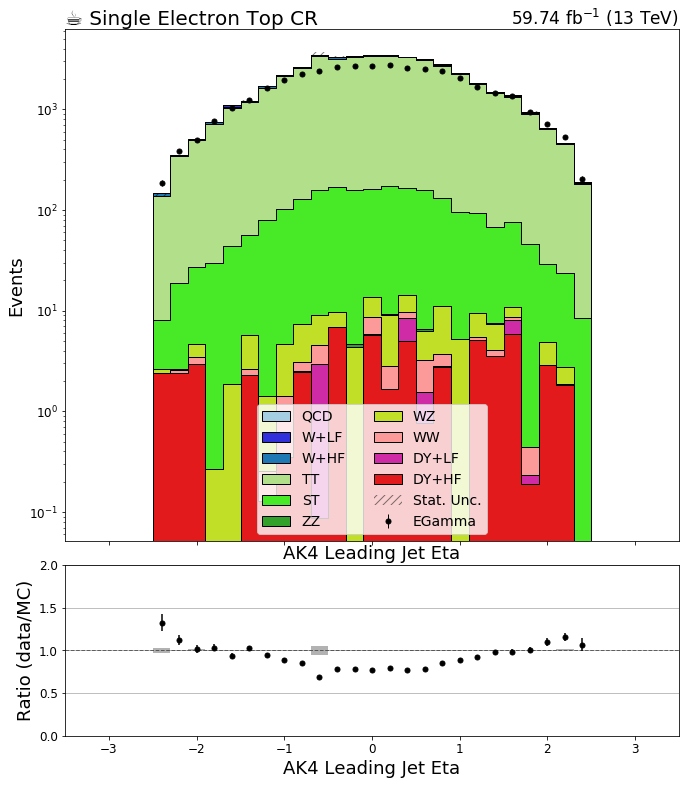

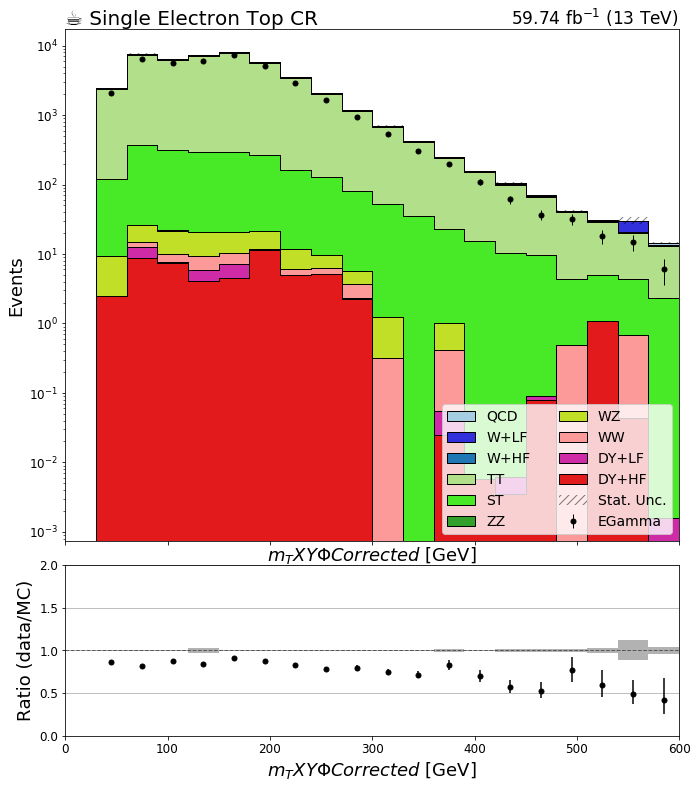

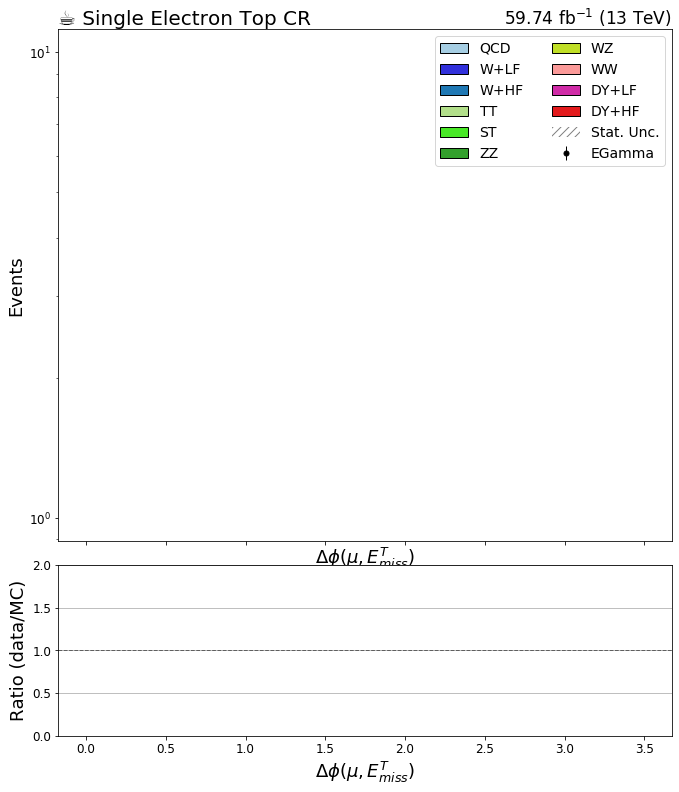

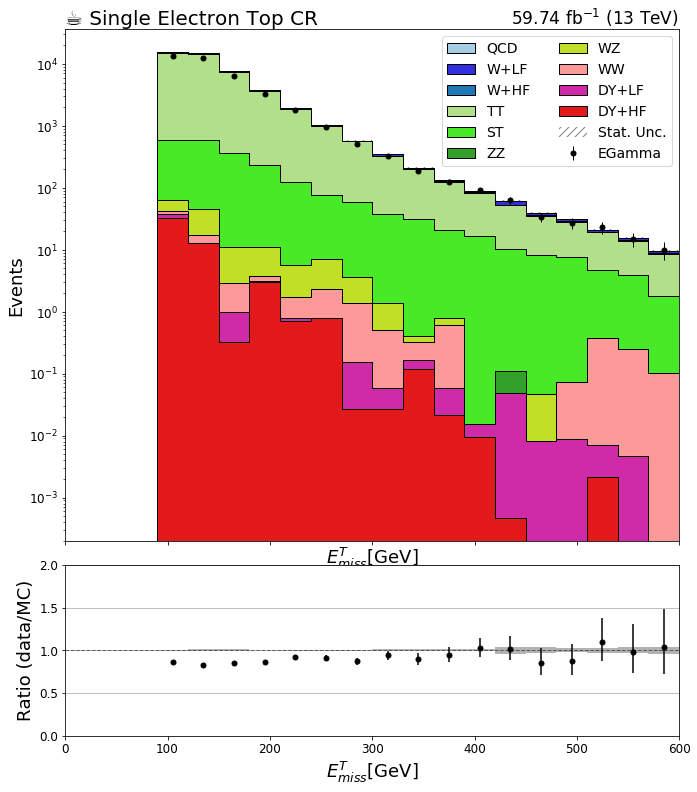

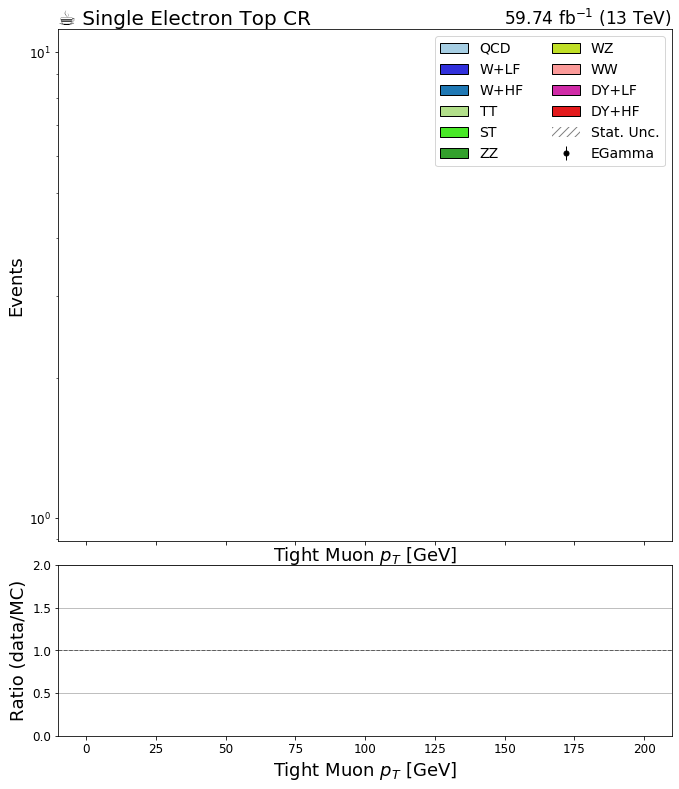

In [15]:
#http://colorbrewer2.org/#type=qualitative&scheme=Paired&n=6 : colors
from cycler import cycler
year = '2018'
region = 'ttbare'
sys = 'nominal'



if not os.path.exists('../plots'):
    os.makedirs('../plots')
R = {}
R['sre'] = 'Signal Region Electron'
R['srm'] = 'Signal Region Muon'
R['wjetm'] = 'Single Muon W CR'
R['ttbarm'] = 'Single Muon Top CR'
R['wjete'] = 'Single Electron W CR'
R['ttbare'] = 'Single Electron Top CR'
# R['zecr'] = 'Double Electron Z CR'
# R['zmcr'] = 'Double Muon Z CR'
# R['gcr'] = 'Single Photon CR'

for key in bkg_hists.keys():
    if key=='sumw': continue
    if key=='template': continue
    if key=='cutflow': continue
    if key=='W_gen_pT':continue
    if key=='Z_gen_pT': continue
    #if key!='fjmass': continue
    for j in bkg_hists[key].identifiers('region'):
        if not (str(j) == region): continue
        plt.rcParams.update({'figure.max_open_warning': 0,'font.size': 14, 'axes.titlesize': 18, 'axes.labelsize': 18, 'xtick.labelsize': 12, 'ytick.labelsize': 12})
        fill_opts = {'edgecolor': (0,0,0,0.3), 'alpha': 1}
        error_opts = {'label':'Stat. Unc.', 'hatch':'///', 'facecolor':'none', 'edgecolor':(0,0,0,.5), 'linewidth': 0}
        nostack_fill_opts = {'alpha': 0.2, 'label': '_nolabel_'}
        data_err_opts = {'linestyle':'None', 'marker': '.', 'markersize': 10., 'color':'k'}#, 'elinewidth': 1, 'emarker': '_'}
        #colors = ['#a6cee3','#1f78b4','#b2df8a','#33a02c','#fb9a99','#e31a1c']
        colors = ['#a6cee3', '#3130db', '#1f78b4', '#b2df8a', '#48e926', '#33a02c', '#c0df26',
                  '#fb9a99', '#d02ba7', '#e31a1c', '#fdbf6f', '#ff7f00', '#cab2d6', '#c64bc4',
                  '#6a3d9a', '#a9ce26', '#ffff99', '#b15928', '#edcc43']


        fig, (ax, rax) = plt.subplots(2, 1, figsize=(11,13), gridspec_kw={"height_ratios": (3, 1)}, sharex=True)
        fig.subplots_adjust(hspace=.07)
        ax.set_prop_cycle(cycler(color=colors))
        
       
        plot.plot1d(data_hists[key].integrate('region',j).integrate('systematic')[data[year][str(j)]],            
                overlay="process",
                ax=ax,
                clear=False,
                error_opts=data_err_opts
                   )

        plot.plot1d(bkg_hists[key].integrate('region',j).integrate('systematic'),
                overlay="process",
                ax=ax,
                clear=False,
                stack=True,
                fill_opts=fill_opts,
                error_opts=error_opts
                   )
        
        plot.plotratio(data_hists[key].integrate('region',j).integrate('systematic').integrate('process',data[year][str(j)]), 
                   bkg_hists[key].integrate('region',j).integrate('systematic').sum('process'),
                   ax=rax,
                   #overflow='over',
                   error_opts=data_err_opts,
                   denom_fill_opts={},
                   guide_opts={},
                   unc='num'
                   )
        
        rax.set_ylabel('Ratio (data/MC)')
        rax.set_ylim(0.0,2.0)
        rax.grid(axis='y')
        
        ax._get_lines.prop_cycler = ax._get_patches_for_fill.prop_cycler
        args = {'linestyle':'--', 'linewidth': 5}
        ax.autoscale(axis='x', tight=True)
        ax.set_yscale('log')
        if(key=='dilepmass'): ax.set_xlim(50, 130)
        ax.set_ylim(.1, None)
        ax.autoscale()
        leg = ax.legend(ncol=2, loc='best')
        
        coffee = plt.text(0., 1., u"☕ "+R[str(j).split('_')[0]], fontsize=20, horizontalalignment='left', verticalalignment='bottom', transform=ax.transAxes)
        lumi = plt.text(1., 1., r"59.74 fb$^{-1}$ (13 TeV)", fontsize=17, horizontalalignment='right', verticalalignment='bottom', transform=ax.transAxes)
        os.system('mkdir -p ../plots/leptonic'+year+'/'+str(j)+'/')
        plot_path = os.path.abspath('../plots/leptonic'+year+'/'+str(j)+'/') 
        plot_name = 'stack_'+key+'.png'
        fig.savefig(os.path.join(plot_path, plot_name))

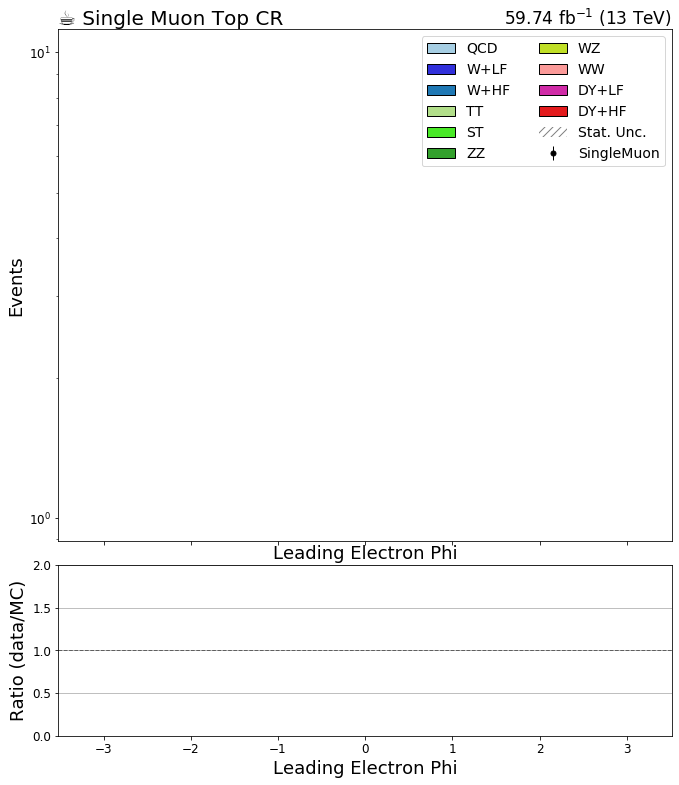

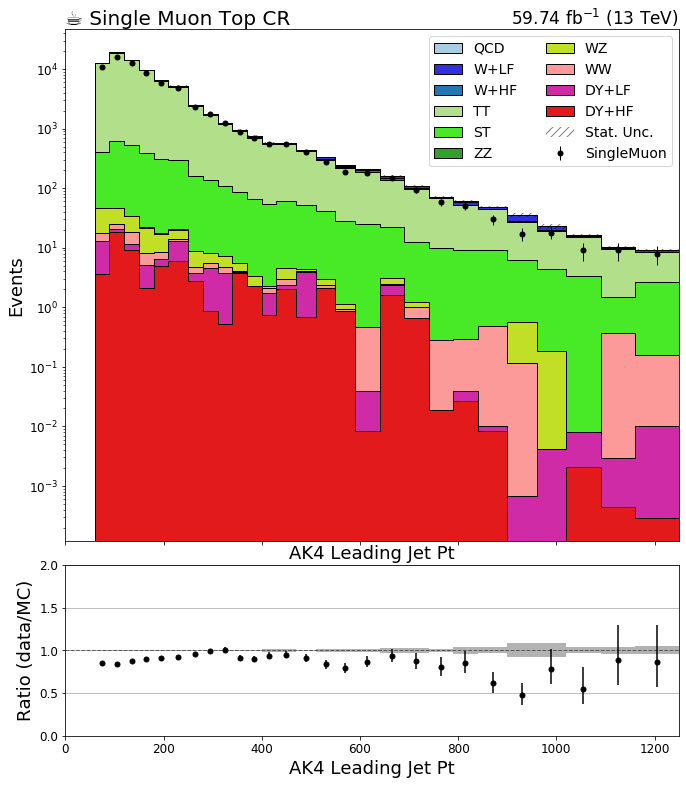

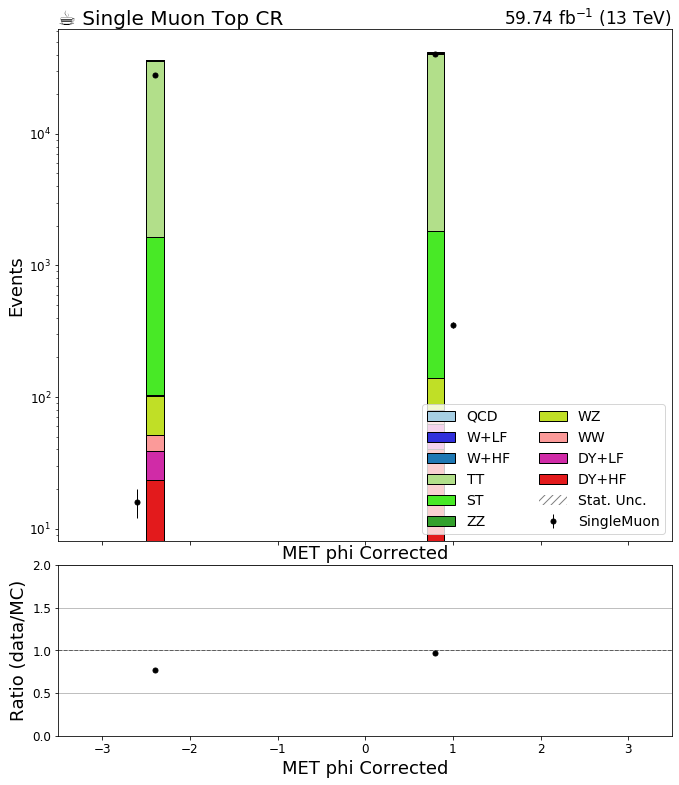

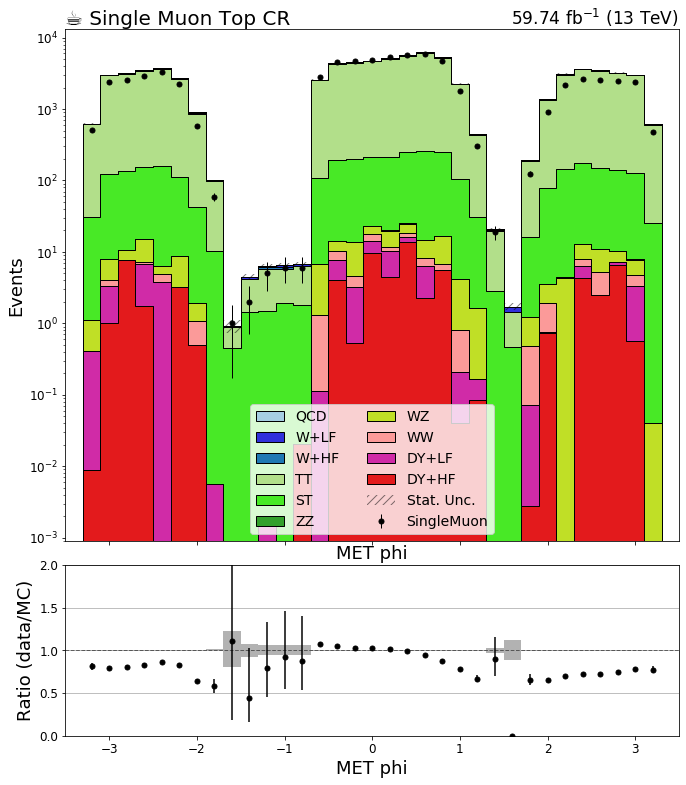

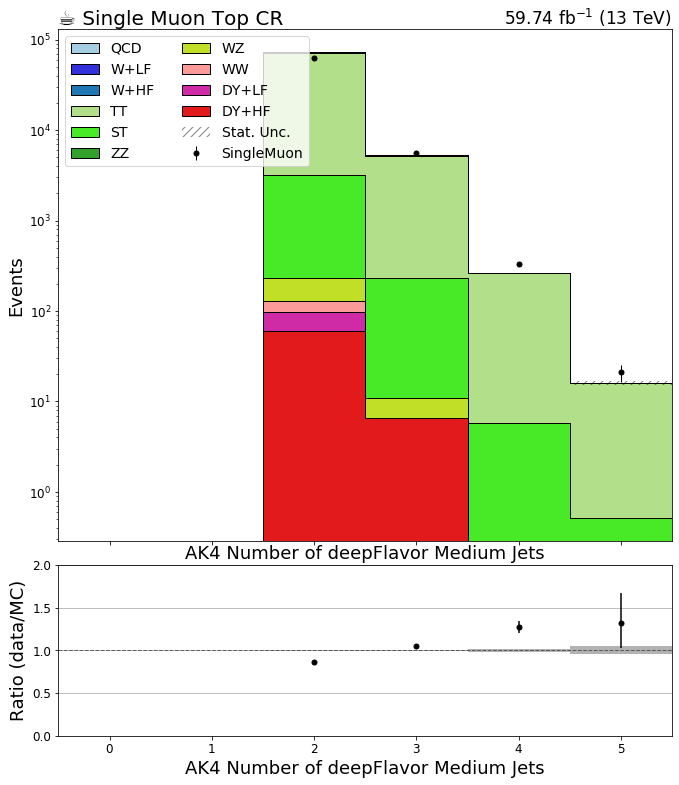

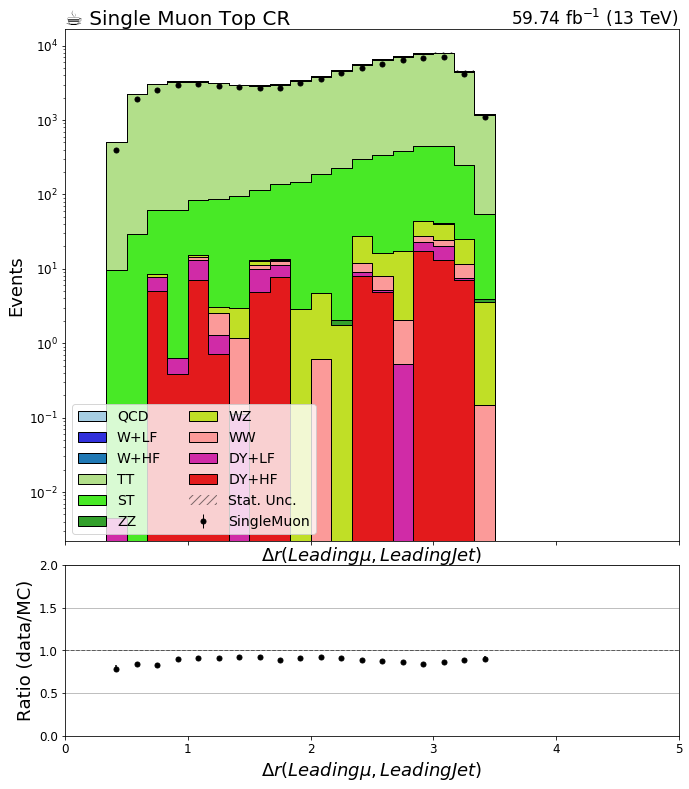

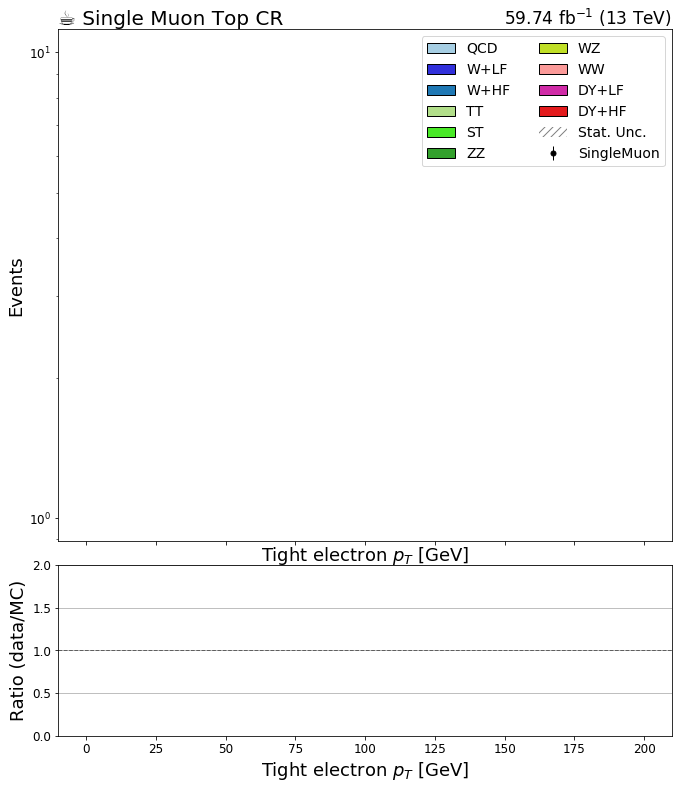

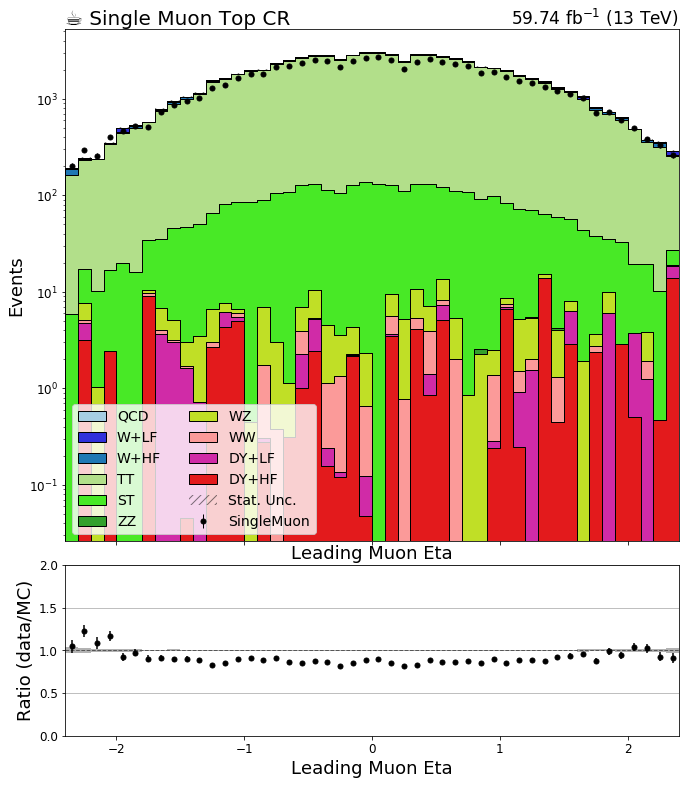

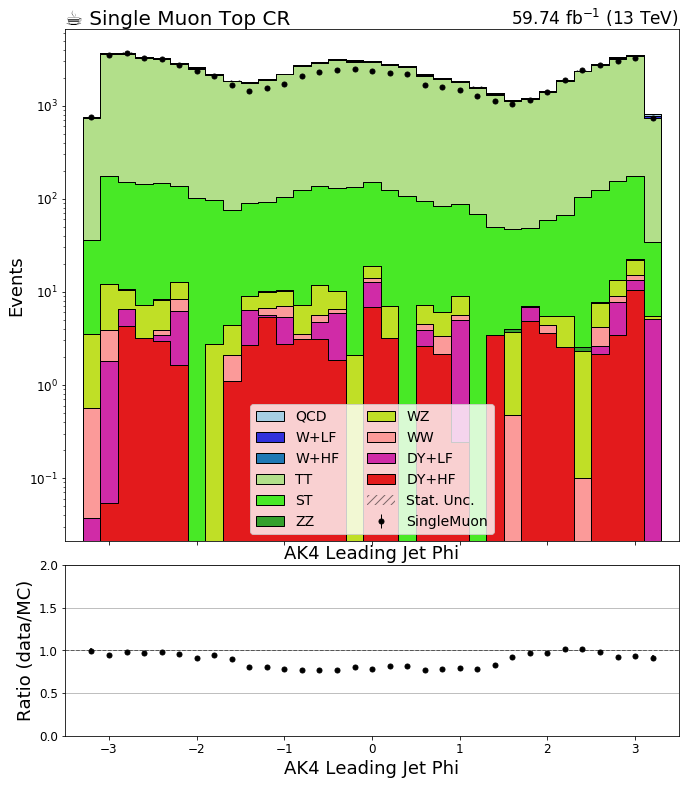

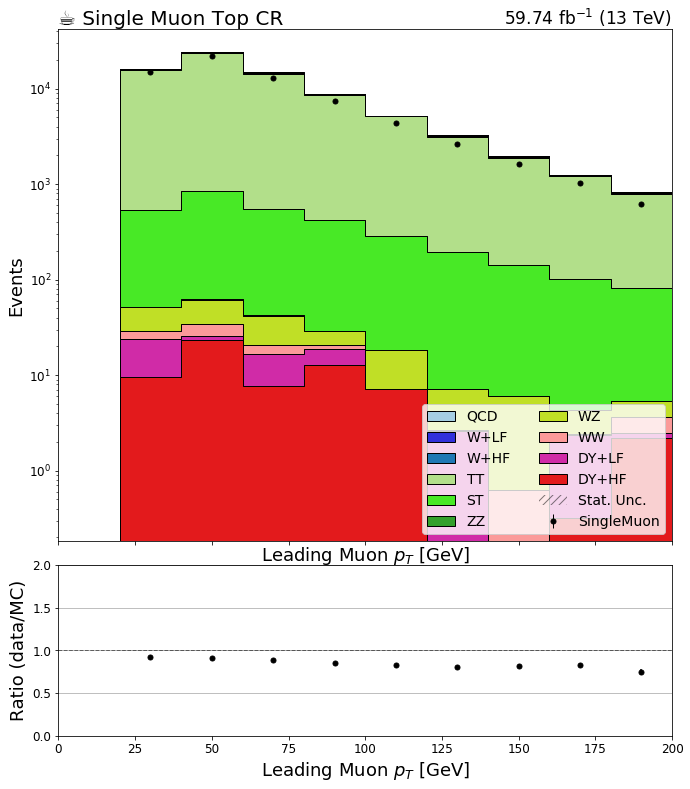

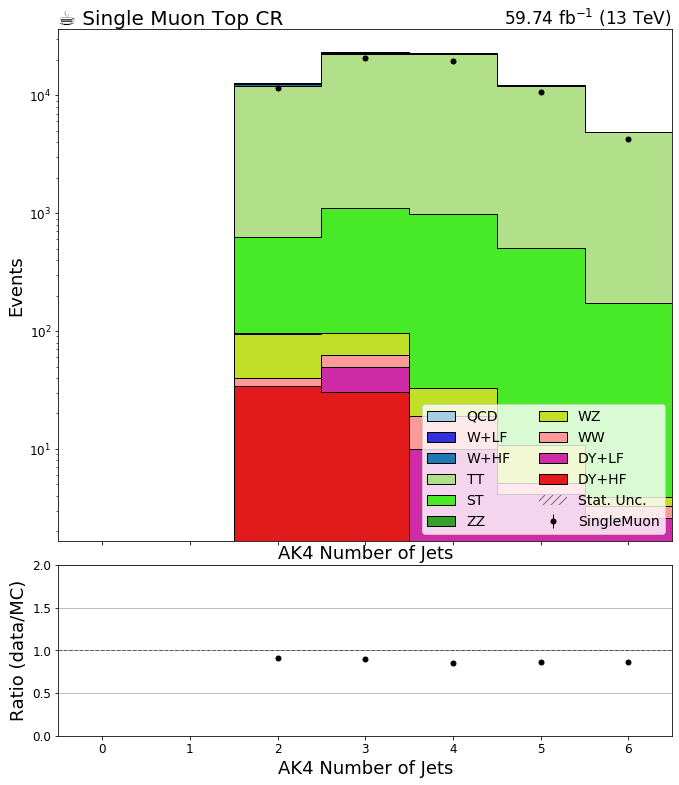

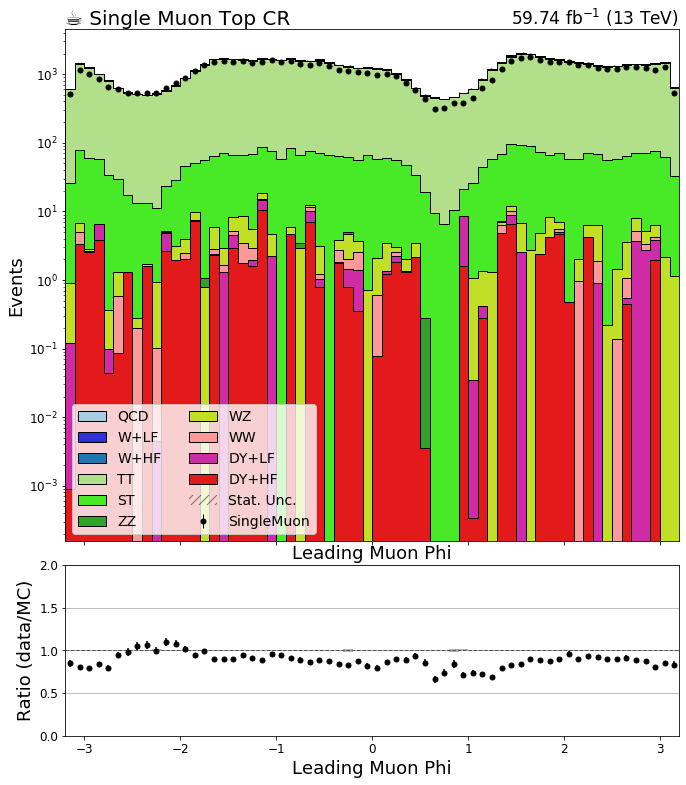

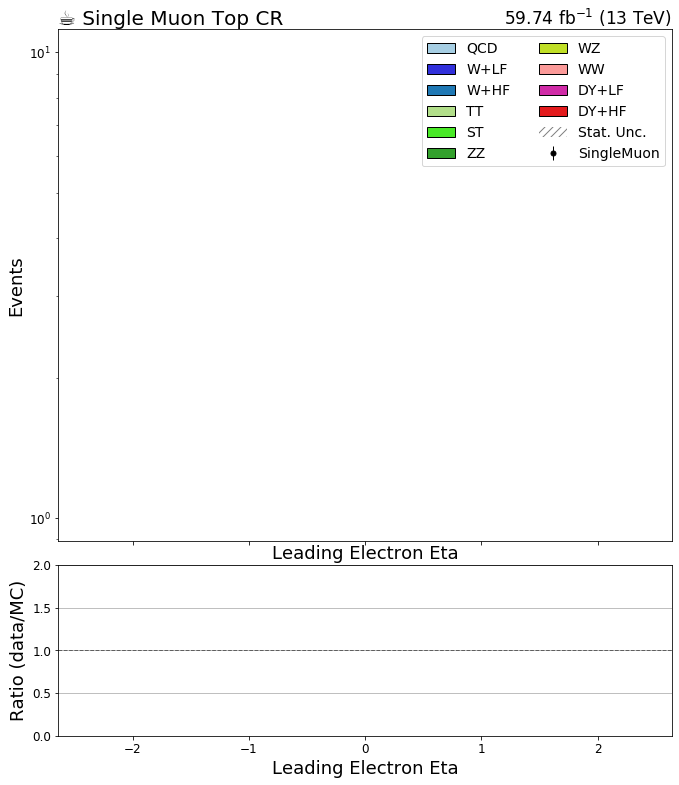

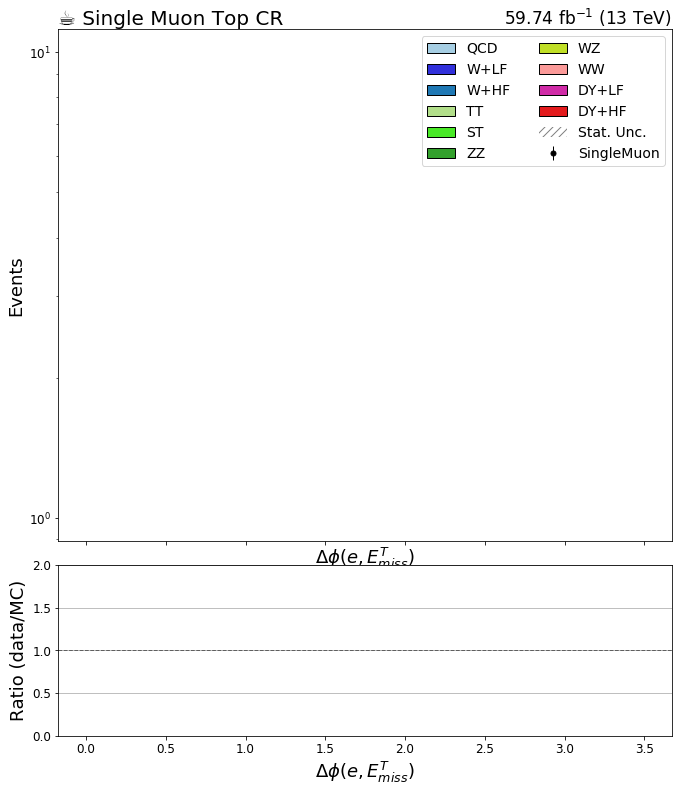

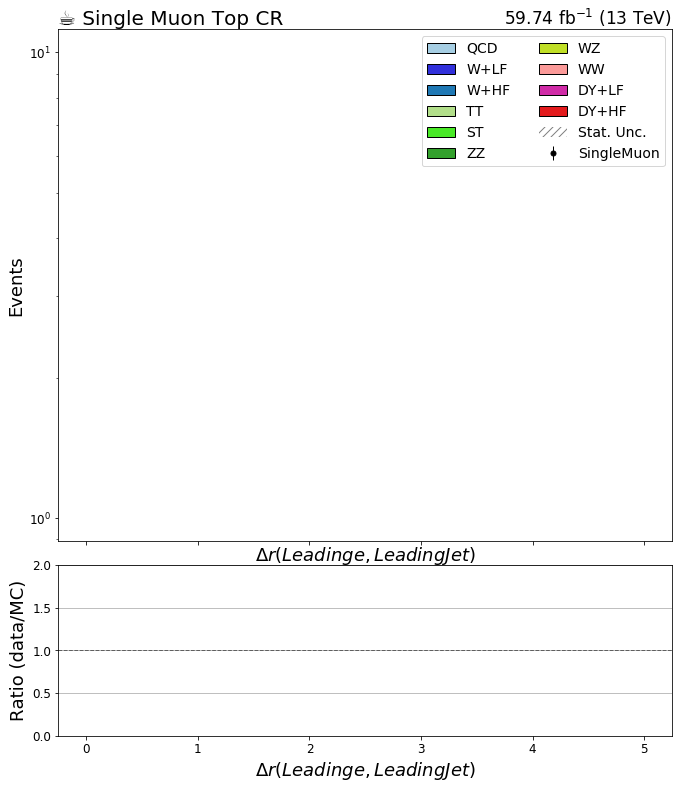

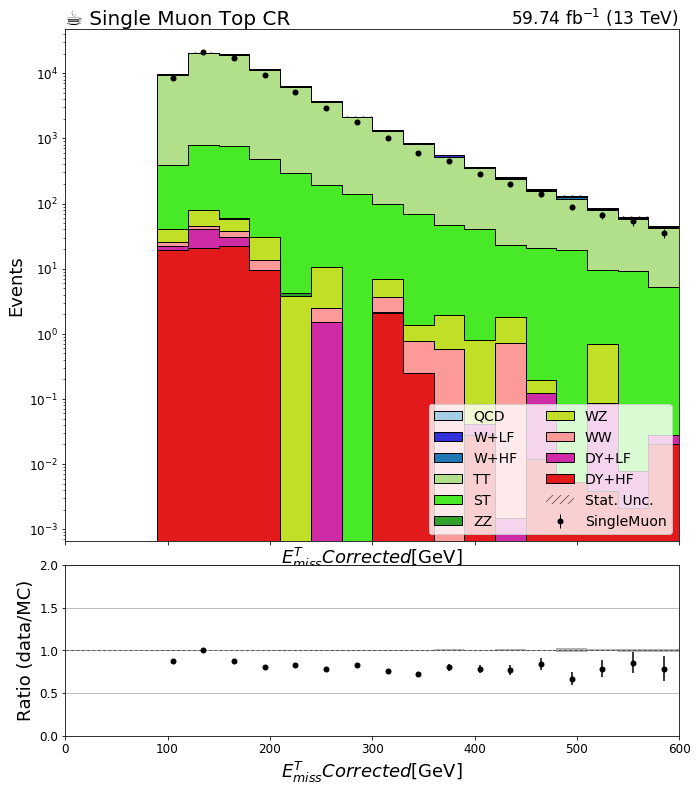

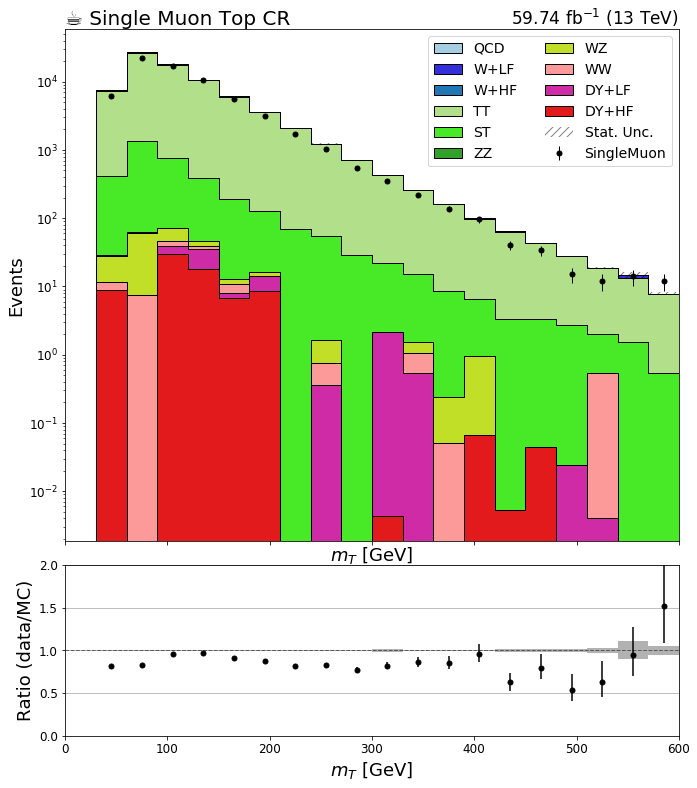

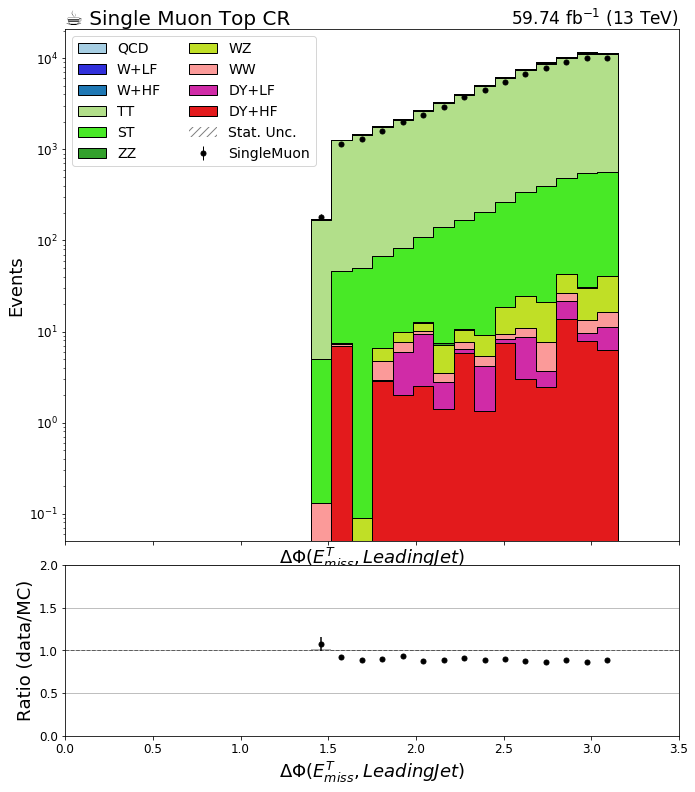

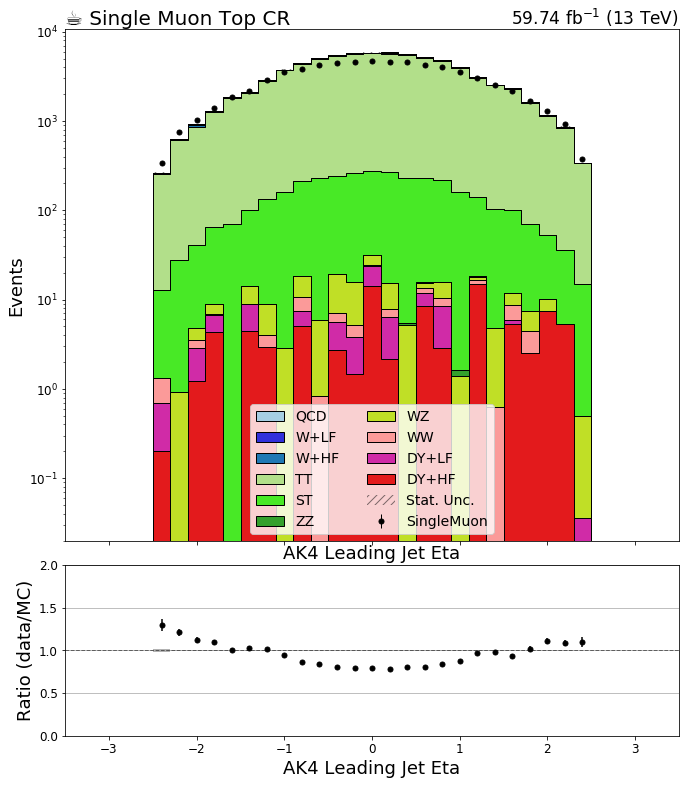

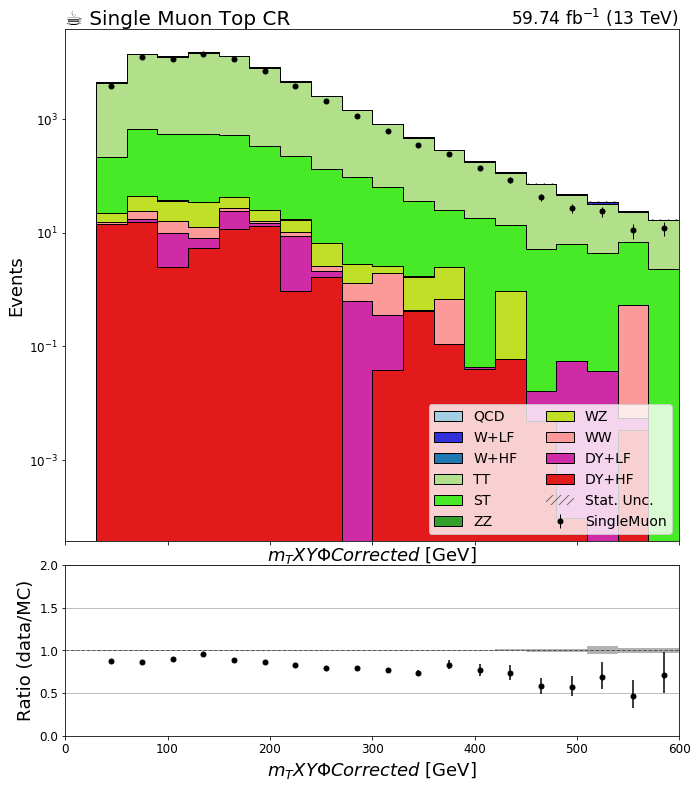

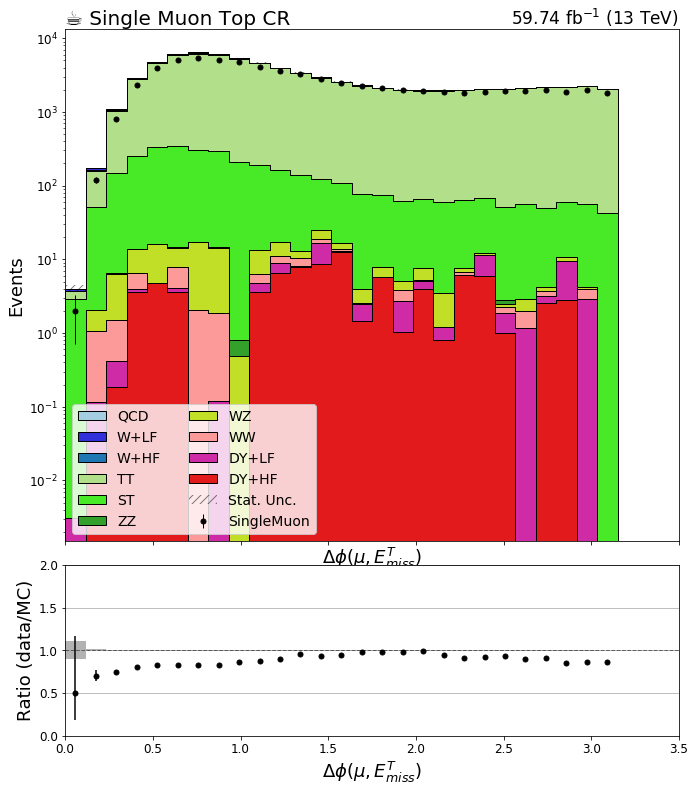

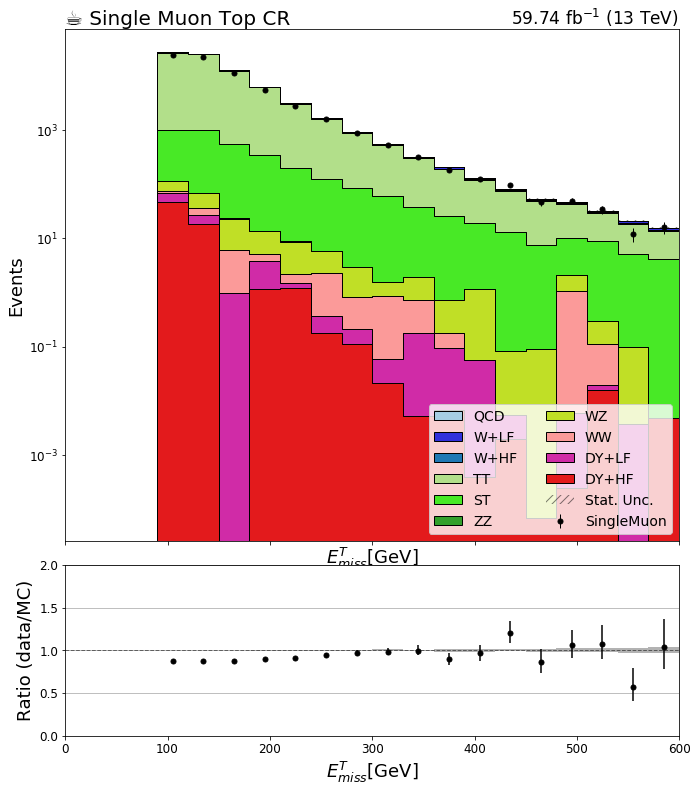

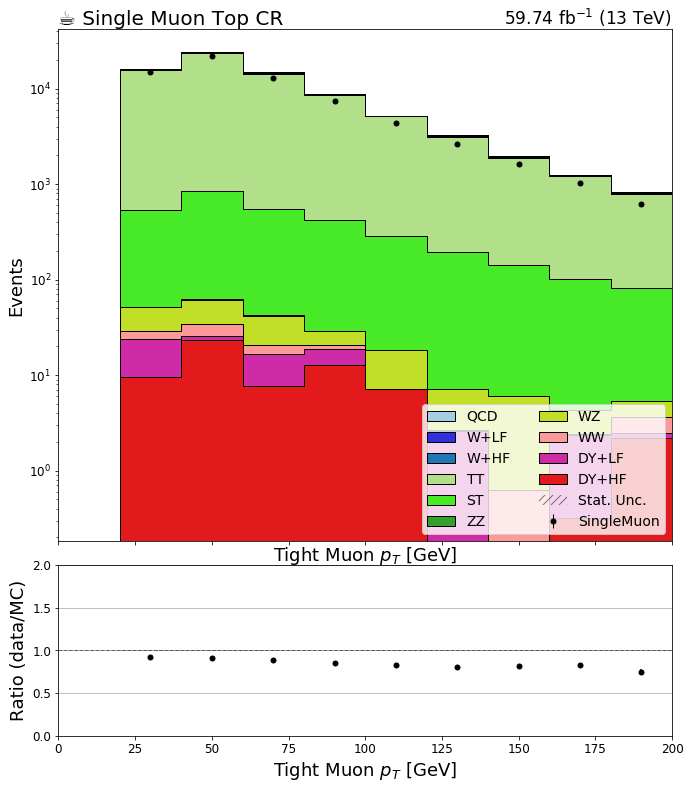

In [17]:
#http://colorbrewer2.org/#type=qualitative&scheme=Paired&n=6 : colors
from cycler import cycler
year = '2018'
region = 'ttbarm'
sys = 'nominal'



if not os.path.exists('../plots'):
    os.makedirs('../plots')
R = {}
R['sre'] = 'Signal Region Electron'
R['srm'] = 'Signal Region Muon'
R['wjetm'] = 'Single Muon W CR'
R['ttbarm'] = 'Single Muon Top CR'
R['wjete'] = 'Single Electron W CR'
R['ttbare'] = 'Single Electron Top CR'
# R['zecr'] = 'Double Electron Z CR'
# R['zmcr'] = 'Double Muon Z CR'
# R['gcr'] = 'Single Photon CR'

for key in bkg_hists.keys():
    if key=='sumw': continue
    if key=='template': continue
    if key=='cutflow': continue
    if key=='W_gen_pT':continue
    if key=='Z_gen_pT': continue
    #if key!='fjmass': continue
    for j in bkg_hists[key].identifiers('region'):
        if not (str(j) == region): continue
        plt.rcParams.update({'figure.max_open_warning': 0,'font.size': 14, 'axes.titlesize': 18, 'axes.labelsize': 18, 'xtick.labelsize': 12, 'ytick.labelsize': 12})
        fill_opts = {'edgecolor': (0,0,0,0.3), 'alpha': 1}
        error_opts = {'label':'Stat. Unc.', 'hatch':'///', 'facecolor':'none', 'edgecolor':(0,0,0,.5), 'linewidth': 0}
        nostack_fill_opts = {'alpha': 0.2, 'label': '_nolabel_'}
        data_err_opts = {'linestyle':'None', 'marker': '.', 'markersize': 10., 'color':'k'}#, 'elinewidth': 1, 'emarker': '_'}
        #colors = ['#a6cee3','#1f78b4','#b2df8a','#33a02c','#fb9a99','#e31a1c']
        colors = ['#a6cee3', '#3130db', '#1f78b4', '#b2df8a', '#48e926', '#33a02c', '#c0df26',
                  '#fb9a99', '#d02ba7', '#e31a1c', '#fdbf6f', '#ff7f00', '#cab2d6', '#c64bc4',
                  '#6a3d9a', '#a9ce26', '#ffff99', '#b15928', '#edcc43']


        fig, (ax, rax) = plt.subplots(2, 1, figsize=(11,13), gridspec_kw={"height_ratios": (3, 1)}, sharex=True)
        fig.subplots_adjust(hspace=.07)
        ax.set_prop_cycle(cycler(color=colors))
        
       
        plot.plot1d(data_hists[key].integrate('region',j).integrate('systematic')[data[year][str(j)]],            
                overlay="process",
                ax=ax,
                clear=False,
                error_opts=data_err_opts
                   )

        plot.plot1d(bkg_hists[key].integrate('region',j).integrate('systematic'),
                overlay="process",
                ax=ax,
                clear=False,
                stack=True,
                fill_opts=fill_opts,
                error_opts=error_opts
                   )
        
        plot.plotratio(data_hists[key].integrate('region',j).integrate('systematic').integrate('process',data[year][str(j)]), 
                   bkg_hists[key].integrate('region',j).integrate('systematic').sum('process'),
                   ax=rax,
                   #overflow='over',
                   error_opts=data_err_opts,
                   denom_fill_opts={},
                   guide_opts={},
                   unc='num'
                   )
        
        rax.set_ylabel('Ratio (data/MC)')
        rax.set_ylim(0.0,2.0)
        rax.grid(axis='y')
        
        ax._get_lines.prop_cycler = ax._get_patches_for_fill.prop_cycler
        args = {'linestyle':'--', 'linewidth': 5}
        ax.autoscale(axis='x', tight=True)
        ax.set_yscale('log')
        if(key=='dilepmass'): ax.set_xlim(50, 130)
        ax.set_ylim(.1, None)
        ax.autoscale()
        leg = ax.legend(ncol=2, loc='best')
        
        coffee = plt.text(0., 1., u"☕ "+R[str(j).split('_')[0]], fontsize=20, horizontalalignment='left', verticalalignment='bottom', transform=ax.transAxes)
        lumi = plt.text(1., 1., r"59.74 fb$^{-1}$ (13 TeV)", fontsize=17, horizontalalignment='right', verticalalignment='bottom', transform=ax.transAxes)
        os.system('mkdir -p ../plots/leptonic'+year+'/'+str(j)+'/')
        plot_path = os.path.abspath('../plots/leptonic'+year+'/'+str(j)+'/') 
        plot_name = 'stack_'+key+'.png'
        fig.savefig(os.path.join(plot_path, plot_name))

In [22]:
bkg_hists['mT_corrected'].integrate('region', 'wjete').integrate('systematic', 'nominal').values()

{('DY+HF',): array([ 0.00000000e+00,  9.63374101e-01,  5.26540097e+00,  4.95909137e+00,
         3.67793546e+00,  3.96008216e+00,  2.75396339e+00,  3.84820391e+00,
         7.25518406e-01,  7.23985509e-01, -2.10981232e-01,  7.78005674e-02,
         5.34442978e-01, -6.10558269e-03,  6.42123018e-03, -4.67688387e-03,
        -8.14310347e-04,  2.97015392e-05,  6.19022582e-03,  2.94016277e-04]),
 ('DY+LF',): array([0.00000000e+00, 2.07061797e+01, 5.43684427e+01, 3.91244676e+01,
        4.80498603e+01, 5.29990282e+01, 2.88156562e+01, 1.96496872e+01,
        9.16133764e+00, 6.56339043e+00, 9.58212400e-01, 1.51194472e+00,
        1.90492130e+00, 1.87198344e+00, 1.11397055e+00, 6.40295110e-01,
        1.57901741e-01, 2.32395594e-01, 4.56816415e-02, 5.32282605e-02]),
 ('WW',): array([ 0.        , 34.39747288, 98.22814361, 73.57893855, 77.0157509 ,
        81.88862825, 50.44785347, 31.26690378, 20.42126188, 11.94330985,
         7.70693917,  5.94347801,  4.4571521 ,  4.01115569,  2.3618505 ,
    

In [42]:
data_hists['template'].integrate('region', 'wjete').integrate('systematic', 'nominal').values()

{('EGamma',): array([    0., 19786., 58413., 47254., 48388., 51229., 29085., 14210.,
         7191.,  3910.,  2219.,  1307.,   842.,   508.,   381.,   243.,
          166.,   123.,    96.,    72.])}

In [44]:
bkg_hists['template'].integrate('region', 'wjete').integrate('systematic').values()

{('DY+HF',): array([ 0.00000000e+00,  3.91040293e+01,  2.26422627e+02,  2.23235185e+02,
         1.68219043e+02,  1.66250823e+02,  1.18063769e+02,  1.68031967e+02,
         2.95734173e+01,  3.12749703e+01, -9.08825204e+00,  3.11538326e+00,
         2.29790086e+01, -2.35529283e-01,  2.40961682e-01, -1.77067309e-01,
        -3.50136918e-02,  9.64401974e-04,  2.66075524e-01,  1.27787094e-02]),
 ('DY+LF',): array([0.00000000e+00, 8.85006337e+02, 2.36811301e+03, 1.75829144e+03,
        2.12061821e+03, 2.29300961e+03, 1.25609600e+03, 8.52023023e+02,
        3.91133948e+02, 2.86142698e+02, 4.26329629e+01, 6.32006245e+01,
        8.31772648e+01, 8.06145405e+01, 4.78815967e+01, 2.75292517e+01,
        6.75795022e+00, 1.00113185e+01, 2.02881304e+00, 2.27846452e+00]),
 ('WW',): array([   0.        ,  566.44640278, 1620.95083099, 1208.72590454,
        1259.9647456 , 1340.45543823,  844.11162209,  515.83953177,
         339.7515046 ,  200.17506058,  132.0771815 ,  100.7049551 ,
          76.936148

In [30]:
data_hists['template']

<Hist (process,region,systematic,mT_corrected) instance at 0x7f5d1a3bf7b8>